# Bend Before Sacks
## Movement leads pressure for every rookie rusher, and Combine tracking previews it for interior linemen

**What this notebook does.** It reproduces every number and figure in our NFL Big Data Bowl 2027 writeup. Regular season games only. Runtime is about six minutes on a standard CPU session, no GPU needed.

**Key outputs**
* A regular season rush signature for every rookie DL from his own tracking, including bend speed and depth toward the quarterback.
* Tests that movement is not just a consequence of winning the rep.
* A context model for expected pressure and pressure over expected.
* A link from Combine tracking to NFL movement and pressure, split by the rusher's alignment on each snap.

**Metric dictionary**
* *Get-off*: seconds from the snap until the rusher crosses the line, from player_play.
* *Speed at t*: rusher speed t seconds after the snap, from game tracking.
* *Depth toward QB at t*: upfield displacement from the snap position, using play direction.
* *Bend speed*: speed at the frame of the rusher's sharpest turn between 0.3 and 3.0 s, where turn rate is speed times change in direction.
* *Pressure*: a recorded time to pressure on that rush. Player rates are shrunk with a beta prior.
* *Pressure over expected*: actual minus a LightGBM expected pressure trained with players held out.
* *Hoop Clock*: time from first movement above 1 yd/s to the end of the Run the Hoop rep.
* *Trench Burst Index*: plain average of four standardized Combine tracking measures, Hoop Clock, 40 yard trace top speed, 40 yard trace peak acceleration in the first second and tracked 10 yard time, oriented so higher is better.
* *Controlled correlation*: Spearman partial correlation after Combine weight, interior or edge roster position and draft pick.

## 1. Setup and helpers

In [1]:
# Libraries
import os, glob, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Display and plot settings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 300)
sns.set_theme(style="whitegrid", context="talk")
# Okabe-Ito colorblind safe palette, plus marker shapes for redundancy
PAL = {"DE": "#0072B2", "OLB": "#E69F00", "DT": "#009E73", "NT": "#CC79A7"}
MK = {"DE": "o", "OLB": "s", "DT": "^", "NT": "D"}
BLUE, ORANGE, GREY, SKY = "#0072B2", "#D55E00", "#9E9E9E", "#56B4E9"
# Load competition files
DATA = os.path.dirname(glob.glob("/kaggle/input/**/players.csv", recursive=True)[0])
players = pd.read_csv(f"{DATA}/players.csv")
combine = pd.read_csv(f"{DATA}/combine_results.csv")
games = pd.read_csv(f"{DATA}/games.csv")
ct = pd.read_csv(f"{DATA}/combine_tracking.csv")
pp = pd.read_csv(f"{DATA}/player_play.csv", low_memory=False)
# Defensive line players and a per player table of draft and Combine info
dl_pos = ["DE", "DT", "NT", "OLB"]
dl_ids = set(players.loc[players.nfl_position.isin(dl_pos), "nfl_id"])
meta = players.set_index("nfl_id")[
    ["display_name", "nfl_position", "draft_overall_pick", "draft_year", "draft_round"]
].join(
    combine.set_index("nfl_id")[
        [
            "combine_weight",
            "combine_height",
            "arm_length",
            "forty",
            "ten_yd_split",
            "three_cone",
            "short_shuttle",
            "vertical",
            "broad_jump",
        ]
    ]
)
# Undrafted players get pick 300. Interior means DT or NT on the roster
meta["pick"] = meta.draft_overall_pick.fillna(300)
meta["interior"] = meta.nfl_position.isin(["DT", "NT"]).astype(int)
# Size and draft controls used in every partial correlation
CTRL = ["combine_weight", "interior", "pick"]


# Helper functions
def kin(df, keys):
    """Add turn rate (omega, rad/s), lateral acceleration (speed x omega) and a frame index per track."""
    df = df.sort_values(keys + ["time"]).copy()
    g = df.groupby(keys, sort=False)
    dd = (g["dir"].diff() + 180) % 360 - 180
    df["omega"] = np.deg2rad(dd.abs()) * 10
    df["omega"] = df.groupby(keys, sort=False)["omega"].transform(
        lambda x: x.rolling(3, center=True, min_periods=1).mean()
    )
    df["lat"] = df["s"] * df["omega"]
    df["fi"] = g.cumcount()
    return df


def partial_multi(x, y, Z):
    """Spearman partial correlation of x and y after regressing the ranks of both on the columns of Z."""
    rx = stats.rankdata(x)
    ry = stats.rankdata(y)
    Zr = np.column_stack([stats.rankdata(z) for z in Z.T] + [np.ones(len(x))])
    ex = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
    ey = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    return stats.pearsonr(ex, ey)


def pc(df, c, o, ctrl=CTRL):
    """Controlled correlation of column c with outcome o. Returns (r, p, n)."""
    x = df[[c, o] + ctrl].dropna()
    r, p = partial_multi(x[c].values, x[o].values, x[ctrl].values)
    return r, p, len(x)


def boot_partial(df, c, o, ctrl=CTRL, B=2000, seed=0):
    """95% bootstrap interval for the controlled correlation, resampling players."""
    x = df[[c, o] + ctrl].dropna()
    rng = np.random.default_rng(seed)
    r = []
    for _ in range(B):
        i = rng.integers(0, len(x), len(x))
        xb = x.iloc[i]
        try:
            r.append(partial_multi(xb[c].values, xb[o].values, xb[ctrl].values)[0])
        except Exception:
            pass
    return np.nanpercentile(r, [2.5, 97.5])


print(games.season_type.value_counts().to_dict())

{'REG': 816, 'PRE': 147, 'POST': 39}


## 2. Regular season rush signature and context model

In [2]:
t0 = time.time()
# Keep regular season games only
reg_games = set(games.loc[games.season_type == "REG", "game_id"])
# Play context columns used later by the expected pressure model
ctxc = [
    "down",
    "yards_to_go",
    "quarter",
    "yardline_number",
    "yardline_side",
    "possession_team",
    "offense_formation",
    "receiver_alignment",
    "team_coverage_man_zone",
    "lined_up_position",
    "blitzing",
    "pre_snap_home_team_win_probability",
    "play_nullified_by_penalty",
    "time_to_pressure",
    "player_get_off",
    "play_direction",
]
# Pass rush definition confirmed by the host: blitzing is True when the player rushed the passer,
# and a dropback has a non-empty pass_result. Get-off is a measure, not part of the definition
blitz_ = pp.blitzing.astype(str).str.strip().str.upper().isin(["TRUE", "1", "1.0"])
passplay_ = pp.pass_result.notna() & (pp.pass_result.astype(str).str.strip() != "")
base_ = (
    pp.nfl_id.isin(dl_ids)
    & pp.game_id.isin(reg_games)
    & (pp.play_nullified_by_penalty.fillna("N") != "Y")
)
# Compare with the earlier definition, a DL snap with a recorded get-off
old_ = base_ & pp.player_get_off.notna()
new_ = base_ & blitz_ & passplay_
print("earlier definition, get-off recorded:", int(old_.sum()))
print(
    pd.crosstab(
        blitz_[old_], passplay_[old_], margins=True, rownames=["blitzing"], colnames=["pass play"]
    )
)
print(
    "pressure rate by group:",
    pp[old_]
    .assign(b=blitz_[old_], p=passplay_[old_])
    .groupby(["b", "p"])
    .time_to_pressure.apply(lambda x: x.notna().mean())
    .round(3)
    .to_dict(),
)
print(
    "new definition, blitzing and pass play:",
    int(new_.sum()),
    " get-off missing:",
    int((new_ & pp.player_get_off.isna()).sum()),
)
rk = pp[new_][["game_id", "play_id", "nfl_id"] + ctxc].copy()
# Read game tracking in chunks and keep DL rushers only
cols = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "dis", "dir", "event"]
parts = []
for yr in [2023, 2024, 2025]:
    for ch in pd.read_csv(f"{DATA}/game_tracking_{yr}.csv", usecols=cols, chunksize=3_000_000):
        parts.append(ch[ch.nfl_id.isin(dl_ids) & ch.game_id.isin(reg_games)])
gt = pd.concat(parts, ignore_index=True)
del parts
# Align every rush to the snap frame (rel = frames after the snap, 10 per second)
K = ["game_id", "play_id", "nfl_id"]
gt = kin(gt.merge(rk[K], on=K), K)
snap = gt[gt.event == "ball_snap"].groupby(K).fi.first().rename("snap_fi")
gt = gt.join(snap, on=K)
gt["rel"] = gt.fi - gt.snap_fi
gt = gt[(gt.rel >= 0) & (gt.rel <= 35)]
# Speed and cumulative distance at fixed times after the snap
piv = gt.pivot_table(index=K, columns="rel", values="s")
cumd = gt.assign(cd=gt.groupby(K).dis.cumsum()).pivot_table(index=K, columns="rel", values="cd")
G = pd.DataFrame(
    {
        "g_s05": piv[5],
        "g_s10": piv[10],
        "g_s15": piv[15],
        "g_s20": piv[20],
        "g_d10": cumd[10],
        "g_d20": cumd[20],
    }
)
# Bend speed: speed at the sharpest turn between 0.3 and 3.0 s, moving faster than 2 yd/s
w = gt[(gt.rel >= 3) & (gt.rel <= 30) & (gt.s > 2)]
G = G.join(
    w.loc[w.groupby(K).lat.idxmax().values, K + ["s"]]
    .set_index(K)
    .rename(columns={"s": "g_v_bend"})
)
# Depth toward the QB: upfield distance from the snap spot, using play direction
gt = gt.merge(rk[K + ["play_direction"]], on=K)
gt["sgn"] = np.where(gt.play_direction == "right", -1.0, 1.0)
gt = gt.join(gt[gt.rel == 0].set_index(K)[["x", "y"]].rename(columns={"x": "x0", "y": "y0"}), on=K)
gt["depth"] = gt.sgn * (gt.x - gt.x0)
dpv = gt.pivot_table(index=K, columns="rel", values="depth")
G = G.join(pd.DataFrame({"dep10": dpv[10], "dep20": dpv[20]}))
# One row per rush: movement + context + outcome
R = G.reset_index().merge(rk, on=K).merge(games[["game_id", "season", "week"]], on="game_id")
R["pressure"] = R.time_to_pressure.notna().astype(int)
R["ydl100"] = np.where(
    R.yardline_side == R.possession_team, 100 - R.yardline_number, R.yardline_number
)
# Categorical context features for LightGBM
cat = ["offense_formation", "receiver_alignment", "team_coverage_man_zone", "lined_up_position"]
for c in cat:
    R[c] = R[c].fillna("NA").astype("category")
FEAT = [
    "down",
    "yards_to_go",
    "quarter",
    "ydl100",
    "pre_snap_home_team_win_probability",
] + cat


# Out of fold predictions with players held out, so no player is scored by a model that saw him
def oof_pred(Xf):
    o = np.zeros(len(R))
    for tr, te in GroupKFold(5).split(Xf, R.pressure, R.nfl_id):
        m = lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=200,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            random_state=0,
            verbose=-1,
        )
        m.fit(Xf.iloc[tr], R.pressure.iloc[tr])
        o[te] = m.predict_proba(Xf.iloc[te])[:, 1]
    return o


# Expected pressure from context only, then context + the rusher's movement
R["xp"] = oof_pred(R[FEAT])
Xm = R[FEAT].copy()
Xm["g_v_bend"] = R.g_v_bend
Xm["g_s10"] = R.g_s10
Xm["g_d20"] = R.g_d20
Xm["player_get_off"] = R.player_get_off
Xm["dep20"] = R.dep20
R["xp_move"] = oof_pred(Xm)
print(
    f"regular season rushes with tracking: {len(R):,}  players: {R.nfl_id.nunique()}  pressure rate {R.pressure.mean():.3f}  time {time.time()-t0:.0f}s"
)
print(
    "rush level AUC, context only: %.3f   context + movement: %.3f"
    % (roc_auc_score(R.pressure, R.xp), roc_auc_score(R.pressure, R.xp_move))
)

earlier definition, get-off recorded: 33417
pass play  False   True    All
blitzing                      
False       8077     46   8123
True          57  25237  25294
All         8134  25283  33417
pressure rate by group: {(False, False): 0.0, (False, True): 0.0, (True, False): 0.018, (True, True): 0.103}
new definition, blitzing and pass play: 27354  get-off missing: 2117
regular season rushes with tracking: 27,349  players: 98  pressure rate 0.099  time 144s
rush level AUC, context only: 0.589   context + movement: 0.732


linked DL with 100+ regular season rushes: 65 {'DT': 24, 'DE': 23, 'OLB': 16, 'NT': 2}  rushes 25960
split half reliability: {'g_s05': np.float64(0.96), 'g_s10': np.float64(0.98), 'g_s15': np.float64(0.98), 'g_s20': np.float64(0.97), 'g_d10': np.float64(0.96), 'g_d20': np.float64(0.98), 'dep10': np.float64(0.97), 'dep20': np.float64(0.98), 'g_v_bend': np.float64(0.92), 'player_get_off': np.float64(0.96), 'pressure': np.float64(0.69)}
                            raw  controlled      p  vs_poe  p_poe  reliability
metric                                                                        
Speed 0.5 s after snap    0.635       0.246  0.048   0.155  0.219        0.959
Speed 1.0 s               0.698       0.372  0.002   0.207  0.098        0.981
Speed 1.5 s               0.656       0.287  0.020   0.150  0.234        0.984
Speed 2.0 s               0.682       0.336  0.006   0.242  0.052        0.969
Distance in 1 s           0.688       0.334  0.007   0.188  0.134        0.961
Distance 

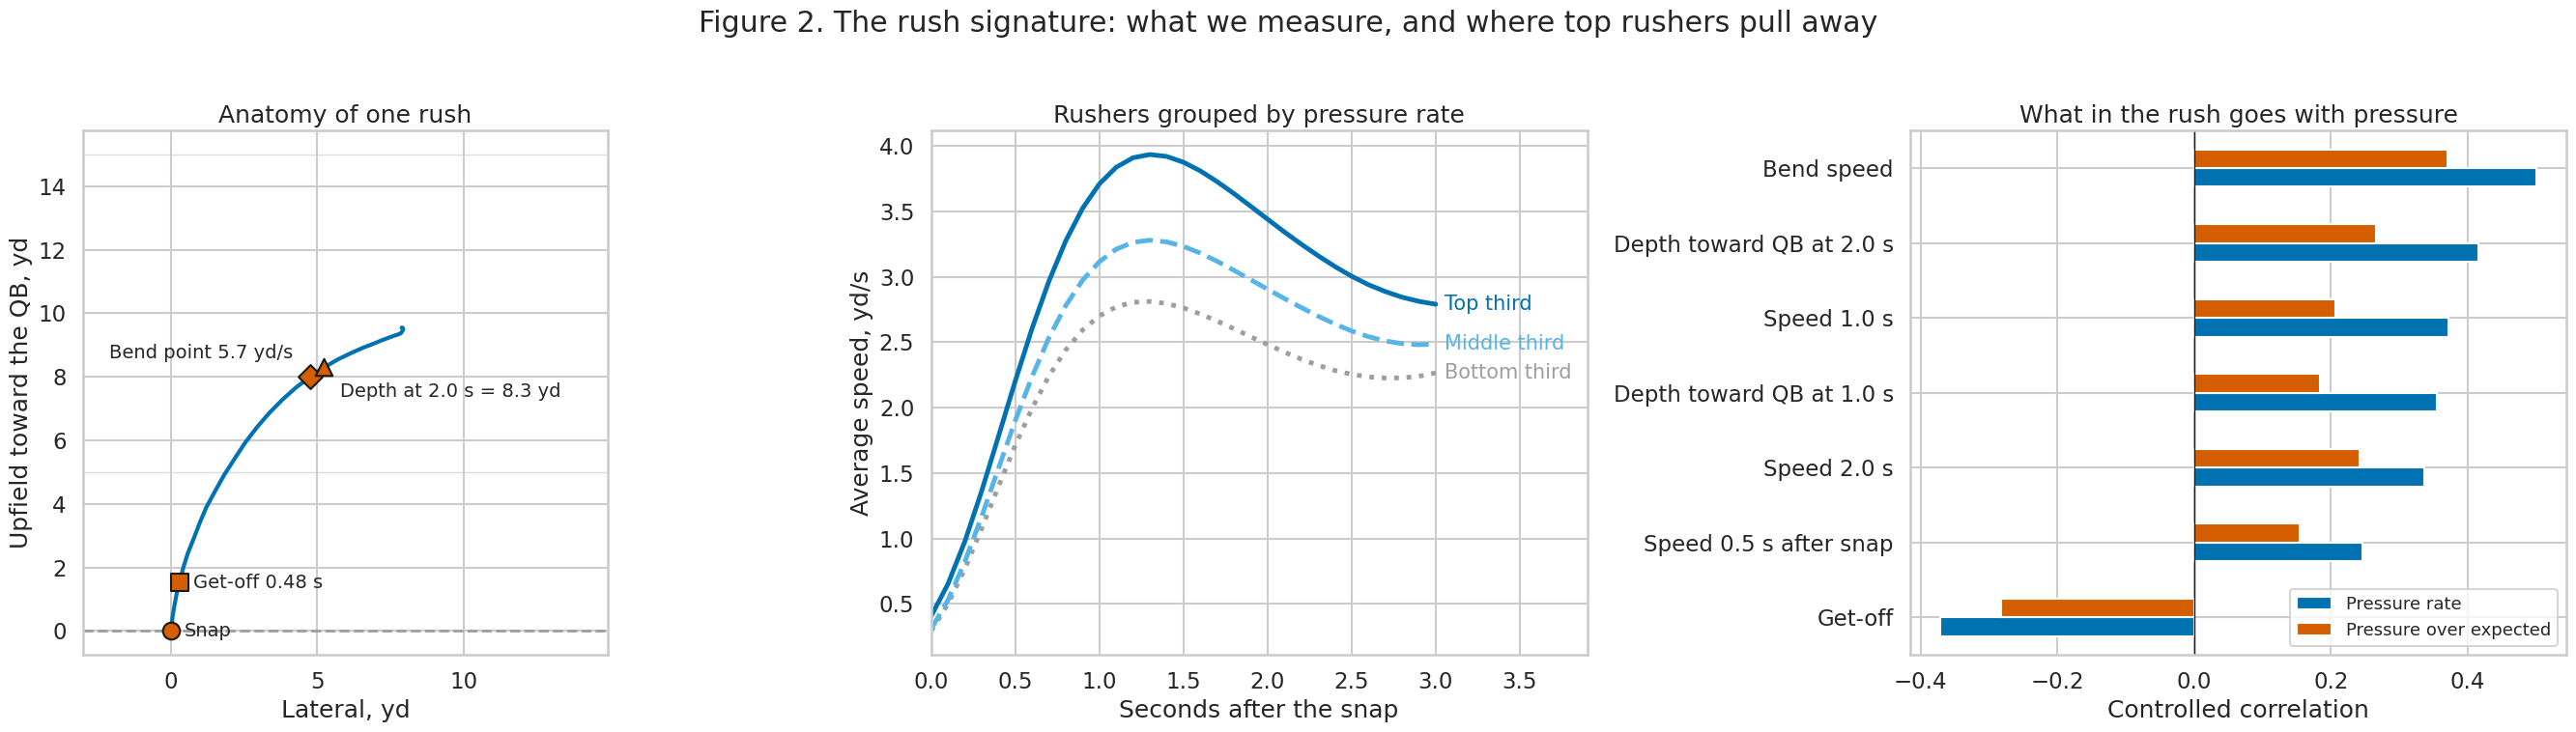

anatomy example: Will Anderson 2025 week 5


In [3]:
# Player level averages of every movement measure
gcols = [
    "g_s05",
    "g_s10",
    "g_s15",
    "g_s20",
    "g_d10",
    "g_d20",
    "dep10",
    "dep20",
    "g_v_bend",
    "player_get_off",
]
GP = R.groupby("nfl_id").agg(
    n_rush=("pressure", "size"),
    n_press=("pressure", "sum"),
    xp_sum=("xp", "sum"),
    **{c: (c, "mean") for c in gcols},
)
# Empirical Bayes shrinkage: fit a beta prior to pressure rates of players with 100+ rushes
p_ = GP.n_press / GP.n_rush
s_ = GP.n_rush >= 100
m_, v_ = p_[s_].mean(), p_[s_].var()
k_ = m_ * (1 - m_) / v_ - 1
a0, b0 = m_ * k_, (1 - m_) * k_
GP["press_eb"] = (GP.n_press + a0) / (GP.n_rush + a0 + b0)
# Pressure over expected per rush, shrunk with the same prior
GP["poe"] = (GP.n_press - GP.xp_sum) / GP.n_rush
GP["poe_eb"] = GP.poe * GP.n_rush / (GP.n_rush + a0 + b0)
# Main sample: linked DL with at least 100 rushes
P = GP[GP.n_rush >= 100].join(meta)
# Split half reliability: alternate rushes into two halves and correlate player means
R["half"] = R.groupby("nfl_id").cumcount() % 2
relg = {}
for c in gcols + ["pressure"]:
    h = R[R.nfl_id.isin(P.index)].groupby(["nfl_id", "half"])[c].mean().unstack()
    relg[c] = stats.pearsonr(h[0], h[1])[0]
print(
    "linked DL with 100+ regular season rushes:",
    len(P),
    P.nfl_position.value_counts().to_dict(),
    " rushes",
    int(P.n_rush.sum()),
)
print("split half reliability:", {k: round(v, 2) for k, v in relg.items()})
labG = {
    "g_s05": "Speed 0.5 s after snap",
    "g_s10": "Speed 1.0 s",
    "g_s15": "Speed 1.5 s",
    "g_s20": "Speed 2.0 s",
    "g_d10": "Distance in 1 s",
    "g_d20": "Distance in 2 s",
    "dep10": "Depth toward QB at 1.0 s",
    "dep20": "Depth toward QB at 2.0 s",
    "g_v_bend": "Bend speed",
    "player_get_off": "Get-off",
}
# Raw and size controlled correlation of each movement measure with pressure
rows = []
for c in gcols:
    r1, p1, n = pc(P, c, "press_eb")
    r2, p2, _ = pc(P, c, "poe_eb")
    rows.append(
        dict(
            metric=labG[c],
            raw=stats.spearmanr(P[c], P.press_eb)[0],
            controlled=r1,
            p=p1,
            vs_poe=r2,
            p_poe=p2,
            reliability=relg[c],
        )
    )
S = pd.DataFrame(rows).set_index("metric")
print(S.round(3))
print("POE vs pressure rate rho", round(stats.spearmanr(P.poe_eb, P.press_eb)[0], 2))
# Figure 1: average speed curve by pressure tercile, and the correlation bars
curve = gt[gt.rel <= 30].merge(P[["press_eb"]].reset_index(), on="nfl_id")
curve["grp"] = pd.qcut(curve.press_eb, 3, labels=["Bottom third", "Middle third", "Top third"])
cv_ = curve.groupby(["grp", "rel"]).s.mean().unstack(0)
# Anatomy panel: one real rush with snap, get-off, bend point and depth at 2.0 s marked
ex_r = R[(R.pressure == 1) & R.g_v_bend.notna()].sort_values("dep20", ascending=False).iloc[40]
tr_ = gt[
    (gt.game_id == ex_r.game_id) & (gt.play_id == ex_r.play_id) & (gt.nfl_id == ex_r.nfl_id)
].sort_values("rel")
lx, ly = (tr_.sgn * (tr_.y - tr_.y0)).values, tr_.depth.values
fig, ax = plt.subplots(1, 3, figsize=(27, 7.5), gridspec_kw={"width_ratios": [0.8, 1, 1]})
ax[0].plot(lx, ly, color=BLUE, lw=3)
for yl in range(0, 16, 5):
    ax[0].axhline(yl, color="#DDDDDD", lw=1, zorder=0)
ax[0].axhline(0, color=GREY, lw=2, ls="--")
i_go = min(int(round(ex_r.player_get_off * 10)), len(lx) - 1)
w_ = tr_[(tr_.rel >= 3) & (tr_.rel <= 30) & (tr_.s > 2)]
i_bd = int(w_.lat.idxmax() - tr_.index[0]) if len(w_) else 0
i_bd = list(tr_.index).index(w_.lat.idxmax()) if len(w_) else 0
i_20 = min(20, len(lx) - 1)
OFFS = {"Snap": (10, -4), "Get-off": (10, -4), "Bend": (-150, 14), "Depth": (12, -22)}
for i_, lab_, mk_ in [
    (0, "Snap", "o"),
    (i_go, f"Get-off {ex_r.player_get_off:.2f} s", "s"),
    (i_bd, f"Bend point {tr_.s.values[i_bd]:.1f} yd/s", "D"),
    (i_20, f"Depth at 2.0 s = {ly[i_20]:.1f} yd", "^"),
]:
    ax[0].scatter(lx[i_], ly[i_], s=160, marker=mk_, color=ORANGE, zorder=5, edgecolor="k")
    ax[0].annotate(
        lab_,
        (lx[i_], ly[i_]),
        xytext=OFFS[lab_.split()[0]],
        textcoords="offset points",
        fontsize=14,
    )
ax[0].set(
    xlabel="Lateral, yd",
    ylabel="Upfield toward the QB, yd",
    title="Anatomy of one rush",
    xlim=(lx.min() - 3, lx.max() + 7),
)
ax = ax[1:]

for c_, col, ls in zip(cv_.columns, [GREY, SKY, BLUE], [":", "--", "-"]):
    ax[0].plot(cv_.index / 10, cv_[c_], lw=3.5, ls=ls, color=col)
ys = cv_.iloc[-1].values.copy()
for i_ in range(1, len(ys)):
    if ys[i_] - ys[i_ - 1] < 0.2:
        ys[i_] = ys[i_ - 1] + 0.2
for (c_, col), yv in zip(zip(cv_.columns, [GREY, SKY, BLUE]), ys):
    ax[0].text(3.05, yv, c_, color=col, fontsize=15, va="center")
ax[0].set(
    xlabel="Seconds after the snap",
    ylabel="Average speed, yd/s",
    title="Rushers grouped by pressure rate",
    xlim=(0, 3.9),
)
S2 = S.drop(["Distance in 1 s", "Distance in 2 s", "Speed 1.5 s"])[
    ["controlled", "vs_poe"]
].sort_values("controlled")
S2.columns = ["Pressure rate", "Pressure over expected"]
S2.plot.barh(ax=ax[1], color=[BLUE, ORANGE])
ax[1].axvline(0, color="k", lw=1)
ax[1].set(
    xlabel="Controlled correlation",
    ylabel="",
    title="What in the rush goes with pressure",
)
ax[1].legend(fontsize=13, loc="lower right")
fig.suptitle(
    "Figure 2. The rush signature: what we measure, and where top rushers pull away", y=1.02
)
plt.tight_layout()
plt.savefig("fig1.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    "anatomy example:",
    meta.loc[ex_r.nfl_id, "display_name"],
    int(ex_r.season),
    "week",
    int(ex_r.week),
)

## 3. Cause or consequence?
If movement after the first second only reflects having already beaten the blocker, it would not predict pressure on other rushes. We measure movement on rushes without pressure, and we cross fit, measuring movement on odd numbered rushes and pressure on even numbered rushes.

In [4]:
# Is movement a cause of pressure or a consequence of winning? Two tests that break the same-play link
newc = ["dep20", "dep10", "g_v_bend", "g_s10", "player_get_off"]
# Test 1: movement measured only on rushes that did NOT produce pressure
GPn = R[R.pressure == 0].groupby("nfl_id")[newc].mean().add_suffix("_np")
# Test 2: cross fit, movement from odd numbered rushes vs pressure on even numbered rushes
R["half"] = R.groupby("nfl_id").cumcount() % 2
odd = R[R.half == 0].groupby("nfl_id")[newc].mean().add_suffix("_odd")
ev = R[R.half == 1].groupby("nfl_id").agg(n_e=("pressure", "size"), p_e=("pressure", "sum"))
ev["press_even"] = (ev.p_e + a0) / (ev.n_e + a0 + b0)
P2 = P.join(GPn).join(odd).join(ev[["press_even"]])
# Compare the links under both tests
rows = []
for c in newc:
    r0, p0, _ = pc(P2, c, "press_eb")
    r1, p1, _ = pc(P2, c + "_np", "press_eb")
    r2, p2, _ = pc(P2, c + "_odd", "press_even")
    r3, p3, _ = pc(P2, c, "poe_eb")
    rows.append(
        {
            "metric": labG[c],
            "all rushes": r0,
            "from non-pressure rushes only": r1,
            "p (non-pressure)": p1,
            "odd rushes -> even rushes": r2,
            "p (cross fit)": p2,
            "vs pressure over expected": r3,
            "p (POE)": p3,
        }
    )
REV = pd.DataFrame(rows).set_index("metric")
print(REV.round(3).to_string())
print(
    "rushes where the player never reached 2 yd/s (no bend value): %.1f%%, pressure rate on them %.3f"
    % (100 * R.g_v_bend.isna().mean(), R[R.g_v_bend.isna()].pressure.mean())
)

                          all rushes  from non-pressure rushes only  p (non-pressure)  odd rushes -> even rushes  p (cross fit)  vs pressure over expected  p (POE)
metric                                                                                                                                                             
Depth toward QB at 2.0 s       0.416                          0.334             0.007                      0.345          0.005                      0.265    0.033
Depth toward QB at 1.0 s       0.354                          0.305             0.014                      0.285          0.022                      0.184    0.142
Bend speed                     0.501                          0.423             0.000                      0.434          0.000                      0.371    0.002
Speed 1.0 s                    0.372                          0.332             0.007                      0.336          0.006                      0.207    0.098
Get-off         

## 4. Movement as a leading indicator

     Speed 1.0 s  Bend speed  Get-off  Pressure
5           0.65        0.40     0.45      0.06
10          0.77        0.57     0.56      0.08
20          0.89        0.74     0.75      0.20
40          0.93        0.85     0.87      0.32
60          0.96        0.90     0.91      0.40
100         0.97        0.94     0.93      0.55  players 42
player seasons 58  median rushes early 96.0  late 217.5
press_E late pressure rho 0.626  late POE rho 0.458
bend_E late pressure rho 0.718  late POE rho 0.353
s10_E late pressure rho 0.712  late POE rho 0.332
getoff_E late pressure rho -0.732  late POE rho -0.413
Early pressure rate            0.374
Early bend speed               0.516
Early pressure + bend speed    0.539
dtype: float64
late POE Early pressure rate            0.158
Early bend speed               0.090
Early pressure + bend speed    0.146
dtype: float64


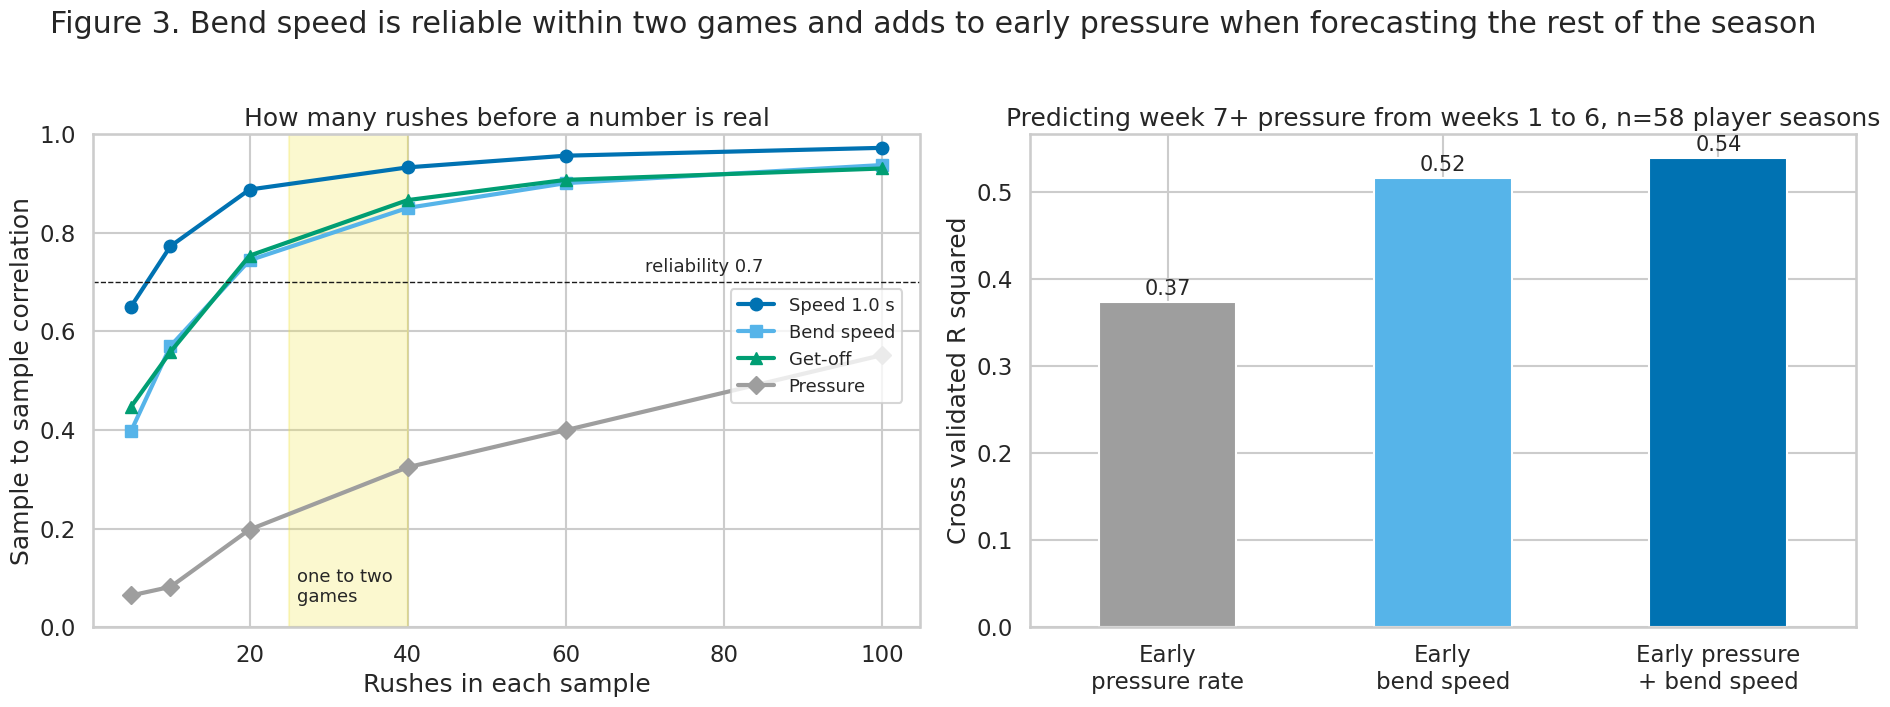

In [5]:
# Stabilization: how many rushes before two samples of the same player agree
big = R[R.nfl_id.isin(GP[GP.n_rush >= 200].index)]
rng = np.random.default_rng(7)
stab = {}
for c, lab in [
    ("g_s10", "Speed 1.0 s"),
    ("g_v_bend", "Bend speed"),
    ("player_get_off", "Get-off"),
    ("pressure", "Pressure"),
]:
    out = {}
    for n in [5, 10, 20, 40, 60, 100]:
        rs = []
        for rep in range(30):
            a = []
            b = []
            for pid, d in big.groupby("nfl_id"):
                v = d[c].dropna().values
                if len(v) < 2 * n:
                    continue
                i = rng.permutation(len(v))
                a.append(v[i[:n]].mean())
                b.append(v[i[n : 2 * n]].mean())
            rs.append(stats.pearsonr(a, b)[0])
        out[n] = np.mean(rs)
    stab[lab] = out
STAB = pd.DataFrame(stab)
print(STAB.round(2), " players", big.nfl_id.nunique())
# Temporal test: weeks 1 to 6 vs week 7 and later, per player season
R["early"] = R.week <= 6
ps = (
    R.groupby(["nfl_id", "season", "early"])
    .agg(
        n=("pressure", "size"),
        press=("pressure", "mean"),
        xs=("xp", "sum"),
        ps_=("pressure", "sum"),
        bend=("g_v_bend", "mean"),
        s10=("g_s10", "mean"),
        getoff=("player_get_off", "mean"),
    )
    .unstack("early")
)
ps.columns = [f'{a}_{"E" if b else "L"}' for a, b in ps.columns]
ps = ps.dropna(subset=["n_E", "n_L"])
ps = ps[(ps.n_E >= 60) & (ps.n_L >= 100)].reset_index()
ps["poe_L"] = (ps.ps__L - ps.xs_L) / ps.n_L
print("player seasons", len(ps), " median rushes early", ps.n_E.median(), " late", ps.n_L.median())
for pred in ["press_E", "bend_E", "s10_E", "getoff_E"]:
    print(
        pred,
        "late pressure rho %.3f  late POE rho %.3f"
        % (stats.spearmanr(ps[pred], ps.press_L)[0], stats.spearmanr(ps[pred], ps.poe_L)[0]),
    )


# Cross validated R squared of a linear forecast
def cvr(cols, yname="press_L"):
    sc = []
    for s in range(50):
        pr = cross_val_predict(
            LinearRegression(),
            ps[cols].values,
            ps[yname].values,
            cv=KFold(5, shuffle=True, random_state=s),
        )
        yv = ps[yname].values
        sc.append(1 - ((yv - pr) ** 2).sum() / ((yv - yv.mean()) ** 2).sum())
    return np.mean(sc)


# Forecast later pressure rate from early pressure, early bend speed, or both
TV = pd.Series(
    {
        "Early pressure rate": cvr(["press_E"]),
        "Early bend speed": cvr(["bend_E"]),
        "Early pressure + bend speed": cvr(["press_E", "bend_E"]),
    }
)
print(TV.round(3))
TV2 = pd.Series(
    {
        "Early pressure rate": cvr(["press_E"], "poe_L"),
        "Early bend speed": cvr(["bend_E"], "poe_L"),
        "Early pressure + bend speed": cvr(["press_E", "bend_E"], "poe_L"),
    }
)
print("late POE", TV2.round(3))
# Figure 2
fig, ax = plt.subplots(1, 2, figsize=(19, 7))
for col, c, mk in zip(STAB.columns, [BLUE, SKY, "#009E73", GREY], ["o", "s", "^", "D"]):
    ax[0].plot(STAB.index, STAB[col], marker=mk, lw=3, ms=9, color=c, label=col)
ax[0].axhline(0.7, ls="--", color="k", lw=1)
ax[0].text(70, 0.72, "reliability 0.7", fontsize=13)
ax[0].axvspan(25, 40, color="#F0E442", alpha=0.25)
ax[0].text(26, 0.05, "one to two\ngames", fontsize=13)
ax[0].set(
    xlabel="Rushes in each sample",
    ylabel="Sample to sample correlation",
    title="How many rushes before a number is real",
    ylim=(0, 1),
)
ax[0].legend(fontsize=13, loc="center right", bbox_to_anchor=(0.99, 0.57))
TV.plot.bar(ax=ax[1], color=[GREY, SKY, BLUE], rot=0)
ax[1].set(
    ylabel="Cross validated R squared",
    title=f"Predicting week 7+ pressure from weeks 1 to 6, n={len(ps)} player seasons",
)
for i_, v in enumerate(TV.values):
    ax[1].text(i_, v + 0.008, f"{v:.2f}", ha="center", fontsize=15)
ax[1].set_xticklabels(["Early\npressure rate", "Early\nbend speed", "Early pressure\n+ bend speed"])
fig.suptitle(
    "Figure 3. Bend speed is reliable within two games and adds to early pressure when forecasting the rest of the season",
    y=1.02,
)
plt.tight_layout()
plt.savefig("fig2.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. The size trap

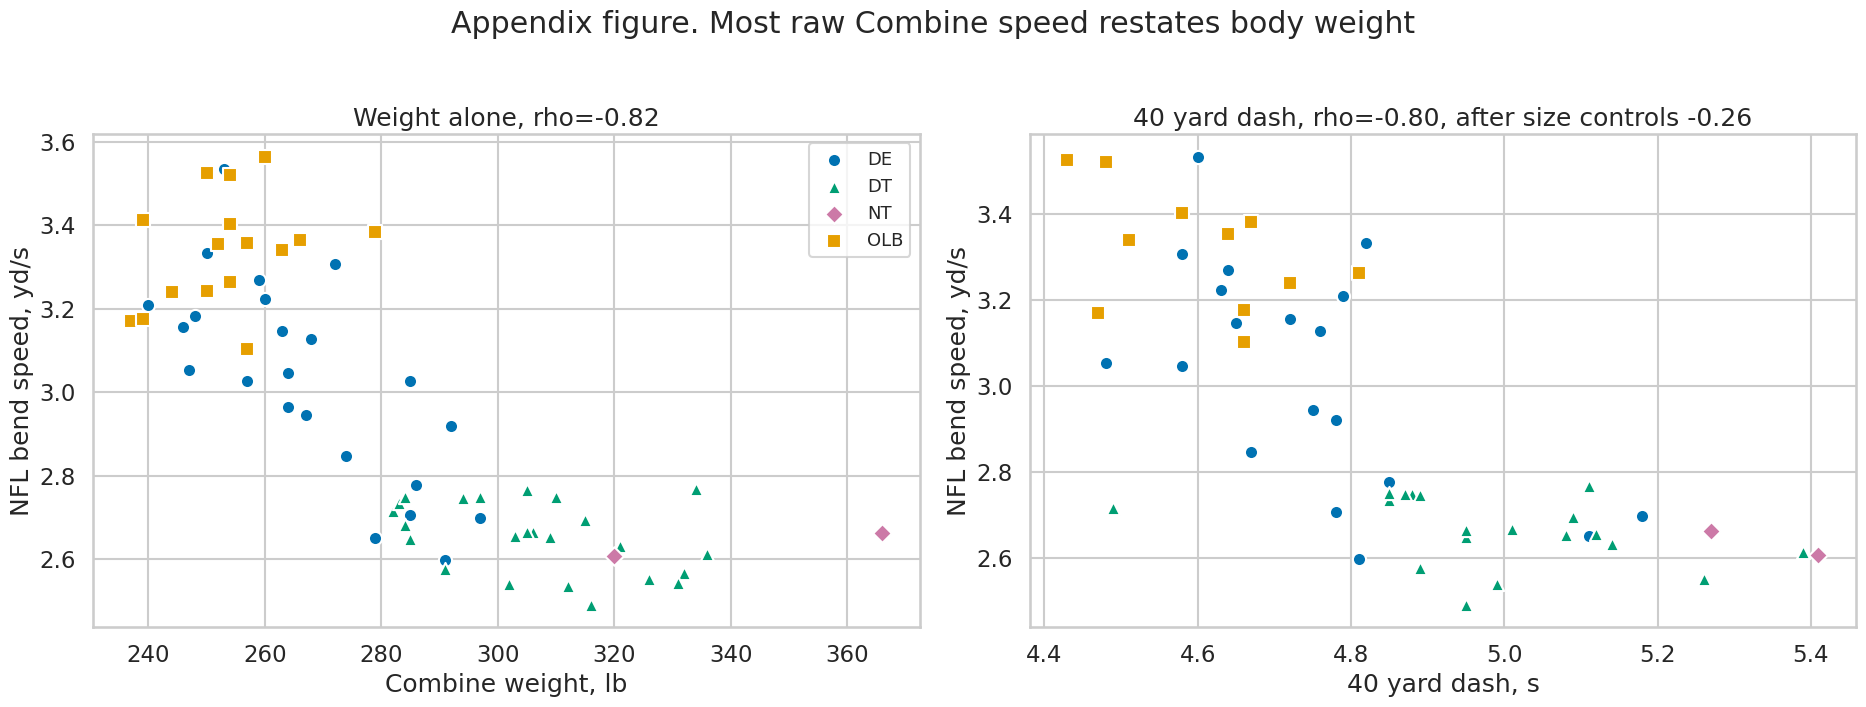

forty vs weight 0.82


In [6]:
# Figure 3: weight and the stopwatch 40 vs NFL bend speed
fig, ax = plt.subplots(1, 2, figsize=(19, 7))
for pos in dl_pos:
    s = P[P.nfl_position == pos]
    ax[0].scatter(
        s.combine_weight, s.g_v_bend, c=PAL[pos], marker=MK[pos], s=90, label=pos, edgecolor="white"
    )
    ax[1].scatter(
        s.forty, s.g_v_bend, c=PAL[pos], marker=MK[pos], s=90, label=pos, edgecolor="white"
    )
ax[0].set(
    xlabel="Combine weight, lb",
    ylabel="NFL bend speed, yd/s",
    title=f"Weight alone, rho={stats.spearmanr(P.combine_weight, P.g_v_bend)[0]:.2f}",
)
ax[0].legend(fontsize=13)
ax[1].set(
    xlabel="40 yard dash, s",
    ylabel="NFL bend speed, yd/s",
    title=f'40 yard dash, rho={stats.spearmanr(P.forty, P.g_v_bend, nan_policy="omit")[0]:.2f}, after size controls {pc(P,"forty","g_v_bend")[0]:.2f}',
)
fig.suptitle("Appendix figure. Most raw Combine speed restates body weight", y=1.02)
plt.tight_layout()
plt.savefig("fig3.png", dpi=150, bbox_inches="tight")
plt.show()
print("forty vs weight", round(stats.spearmanr(P.forty, P.combine_weight, nan_policy="omit")[0], 2))

## 6. Combine tracking measures

In [7]:
# Combine DL drill features from tracking: burst in every drill, Hoop Clock, Pass Rush corner
dl = kin(ct[(ct.entity_type == "PLAYER") & (ct.drill_type == "SKILL_DRILLS_DL")], ["event_id"])
rows = []
for (eid, dn), d in dl.groupby(["event_id", "drill_name"]):
    s = d.s.values
    lat = d.lat.values
    n = len(s)
    on = np.argmax(s > 1.0) if (s > 1.0).any() else 0
    r = dict(
        event_id=eid, nfl_id=d.nfl_id.iloc[0], drill=dn, attempt=d.attempt.iloc[0], vmax=s.max()
    )
    k5 = np.where(s[on:] >= 5)[0]
    r["t5"] = k5[0] / 10 if len(k5) else np.nan
    if dn == "RUN_THE_HOOP_DRILL" and n >= 40:
        r.update(hoop_clock=(n - on) / 10, hoop_window=n / 10)
    if dn == "PASS_RUSH_DRILL" and n >= 25:
        b = 5 + np.argmax(lat[5 : n - 5])
        r.update(rush_corner_speed=s[b], rush_corner_bend=lat[b])
    rows.append(r)
E = pd.DataFrame(rows)
# Standardize burst within each drill so drills are comparable
for m in ["vmax", "t5"]:
    E[m + "_z"] = E.groupby("drill")[m].transform(lambda x: (x - x.mean()) / x.std())
# 40 yard dash trace: top speed, tracked 10 yard time, peak acceleration in the first second
f40 = ct[(ct.entity_type == "PLAYER") & (ct.drill_type == "FORTY_YARD_DASH")].sort_values(
    ["event_id", "time"]
)
rows = []
for eid, d in f40.groupby("event_id"):
    s = d.s.values
    a = d.a.values
    cd = np.cumsum(d.dis.values)
    if not (s > 0.5).any():
        continue
    on = np.argmax(s > 0.5)
    k10 = np.where(cd - cd[on] >= 10)[0]
    rows.append(
        dict(
            nfl_id=d.nfl_id.iloc[0],
            t40_vmax=s.max(),
            t40_ten=(k10[0] - on) / 10 if len(k10) else np.nan,
            t40_acc1=a[on : on + 10].max(),
        )
    )
F40 = (
    pd.DataFrame(rows)
    .groupby("nfl_id")
    .agg(t40_vmax=("t40_vmax", "max"), t40_ten=("t40_ten", "min"), t40_acc1=("t40_acc1", "max"))
)
# One row per player with every Combine tracking feature
C = (
    E.groupby("nfl_id")[["vmax_z", "t5_z"]]
    .mean()
    .join(
        E.groupby("nfl_id")[
            ["hoop_clock", "hoop_window", "rush_corner_speed", "rush_corner_bend"]
        ].mean()
    )
    .join(F40, how="outer")
)
C = C[C.index.isin(dl_ids)]
# 2025 Combine tracking is a different export, so center every tracking measure within its draft class
C_raw = C.copy()
yr_ = meta.draft_year.reindex(C.index)
print(
    "class means before centering:",
    C_raw.join(yr_)
    .groupby("draft_year")[["hoop_clock", "t40_vmax", "t40_acc1", "t40_ten"]]
    .mean()
    .round(2)
    .to_dict(),
)
for col_ in C.columns:
    adj_ = C[col_] - C[col_].groupby(yr_).transform("mean") + C[col_].mean()
    C[col_] = adj_.fillna(C[col_])
# Trench Burst Index: plain average of four standardized measures, higher = better
zs = lambda s: (s - s.mean()) / s.std()
Zc = pd.DataFrame(
    {"h": -zs(C.hoop_clock), "v": zs(C.t40_vmax), "a": zs(C.t40_acc1), "t": -zs(C.t40_ten)}
)
C["cmi"] = Zc.mean(axis=1, skipna=True).where(Zc.notna().sum(axis=1) >= 1)
Q = P.join(C)
# Labels and sign so that positive always means faster or better
labC = {
    "cmi": "Trench Burst Index, 4 tracking measures",
    "hoop_clock": "Hoop Clock",
    "hoop_window": "Hoop Clock, full window",
    "t40_vmax": "40 trace: top speed",
    "t40_ten": "40 trace: tracked 10 yd",
    "t40_acc1": "40 trace: peak accel",
    "vmax_z": "All DL drills: top speed",
    "t5_z": "All DL drills: time to 5 yd/s",
    "rush_corner_speed": "Pass Rush drill: corner speed",
    "rush_corner_bend": "Pass Rush drill: corner bend",
    "forty": "Stopwatch 40",
    "ten_yd_split": "Stopwatch 10 yd",
    "three_cone": "Stopwatch 3-cone",
    "short_shuttle": "Stopwatch shuttle",
    "broad_jump": "Broad jump",
    "vertical": "Vertical",
}
better = {
    "cmi": 1,
    "hoop_clock": -1,
    "hoop_window": -1,
    "t40_vmax": 1,
    "t40_ten": -1,
    "t40_acc1": 1,
    "vmax_z": 1,
    "t5_z": -1,
    "rush_corner_speed": 1,
    "rush_corner_bend": 1,
    "forty": -1,
    "ten_yd_split": -1,
    "three_cone": -1,
    "short_shuttle": -1,
    "broad_jump": 1,
    "vertical": 1,
}
# Controlled correlation of every Combine measure with every NFL outcome
outs = ["g_v_bend", "g_s05", "g_s10", "player_get_off", "press_eb", "poe_eb"]
labO = {**labG, "press_eb": "Pressure rate", "poe_eb": "Pressure over expected"}
sgn = {"player_get_off": -1}
M = pd.DataFrame(index=[labC[c] for c in labC], columns=[labO[o] for o in outs], dtype=float)
Pm = M.copy()
Nn = {}
for c in labC:
    for o in outs:
        r, p, n = pc(Q, c, o)
        M.loc[labC[c], labO[o]] = r * better[c] * sgn.get(o, 1)
        Pm.loc[labC[c], labO[o]] = p
        Nn[labC[c]] = n
print(M.round(2).to_string())
print(pd.Series(Nn))
print("full scan table above, all linked DL. Figure 4 below splits by alignment.")

class means before centering: {'hoop_clock': {2023: 7.14, 2024: 7.19, 2025: 7.31}, 't40_vmax': {2023: 10.16, 2024: 10.02, 2025: 10.05}, 't40_acc1': {2023: 5.67, 2024: 5.77, 2025: 4.93}, 't40_ten': {2023: 2.5, 2024: 2.51, 2025: 2.64}}
                                         Bend speed  Speed 0.5 s after snap  Speed 1.0 s  Get-off  Pressure rate  Pressure over expected
Trench Burst Index, 4 tracking measures        0.25                    0.09         0.23     0.22           0.32                    0.19
Hoop Clock                                     0.31                    0.24         0.26     0.22           0.26                    0.14
Hoop Clock, full window                        0.28                    0.35         0.31     0.21           0.13                   -0.00
40 trace: top speed                            0.26                    0.03         0.20     0.28           0.30                    0.21
40 trace: tracked 10 yd                        0.08                    0.03      

In [8]:
# family wise check on bend speed, the primary target
# Permutation test: shuffle the outcome, record the best of all candidates, repeat
cand = [c for c in labC if c != "cmi"]
rng = np.random.default_rng(11)


def maxabs(yv):
    best = 0
    for c in cand:
        x = Q[[c] + CTRL].assign(y=yv).dropna()
        if len(x) < 20:
            continue
        best = max(best, abs(partial_multi(x[c].values, x.y.values, x[CTRL].values)[0]))
    return best


for o in ["g_v_bend", "player_get_off", "press_eb"]:
    null = np.array([maxabs(rng.permutation(Q[o].values)) for _ in range(500)])
    obs = {c: abs(pc(Q, c, o)[0]) for c in ["hoop_clock", "hoop_window", "t40_vmax", "forty"]}
    print(
        labO[o],
        {labC[c]: (round(v, 3), round(np.mean(null >= v), 3)) for c, v in obs.items()},
        " null 95th",
        round(np.percentile(null, 95), 3),
    )

Bend speed {'Hoop Clock': (np.float64(0.308), np.float64(0.46)), 'Hoop Clock, full window': (np.float64(0.282), np.float64(0.57)), '40 trace: top speed': (np.float64(0.265), np.float64(0.662)), 'Stopwatch 40': (np.float64(0.26), np.float64(0.684))}  null 95th 0.481
Get-off {'Hoop Clock': (np.float64(0.221), np.float64(0.858)), 'Hoop Clock, full window': (np.float64(0.206), np.float64(0.894)), '40 trace: top speed': (np.float64(0.282), np.float64(0.572)), 'Stopwatch 40': (np.float64(0.341), np.float64(0.314))}  null 95th 0.479
Pressure rate {'Hoop Clock': (np.float64(0.264), np.float64(0.67)), 'Hoop Clock, full window': (np.float64(0.134), np.float64(0.994)), '40 trace: top speed': (np.float64(0.3), np.float64(0.512)), 'Stopwatch 40': (np.float64(0.353), np.float64(0.302))}  null 95th 0.493


In [9]:
# Block test: does the whole set of Combine tracking measures add out of sample prediction beyond size? (no single feature picked)
# Block test: all tracking measures at once in a cross validated ridge model vs size alone
TRK = [
    "hoop_clock",
    "hoop_window",
    "t40_vmax",
    "t40_ten",
    "t40_acc1",
    "vmax_z",
    "t5_z",
    "rush_corner_speed",
    "rush_corner_bend",
]
STW = ["forty", "ten_yd_split", "broad_jump", "vertical"]


def oof_r2(df, feats, y, seeds=20):
    X = df[feats].copy()
    X = X.fillna(X.median())
    yv = df[y].values
    sc = []
    for s in range(seeds):
        pr = cross_val_predict(
            make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 40))),
            X.values,
            yv,
            cv=KFold(5, shuffle=True, random_state=s),
        )
        sc.append(1 - ((yv - pr) ** 2).sum() / ((yv - yv.mean()) ** 2).sum())
    return np.mean(sc)


# Players with at least three tracking measures, missing values filled with the median
D = Q[Q[TRK].notna().sum(axis=1) >= 3].copy()
print("players with 3+ tracking measures", len(D))
rngb = np.random.default_rng(21)
BT = {}
for y in ["g_v_bend", "g_s05", "player_get_off", "press_eb", "poe_eb"]:
    base = oof_r2(D, CTRL, y, 10)
    trk = oof_r2(D, CTRL + TRK, y, 10)
    stw = oof_r2(D, CTRL + STW, y, 10)
    both = oof_r2(D, CTRL + STW + TRK, y, 10)
    null = []
    for _ in range(200):
        Dp = D.copy()
        Dp[TRK] = D[TRK].values[rngb.permutation(len(D))]
        null.append(oof_r2(Dp, CTRL + TRK, y, 2) - base)
    BT[labO[y]] = dict(
        size_only=base,
        plus_tracking=trk,
        gain=trk - base,
        perm_p=np.mean(np.array(null) >= trk - base),
        plus_stopwatch=stw,
        stopwatch_plus_tracking=both,
    )
BT = pd.DataFrame(BT).T
print(BT.round(3))
# Trench Burst Index with bootstrap intervals
for o in ["g_v_bend", "g_s05", "player_get_off", "press_eb", "poe_eb"]:
    r, p, n = pc(Q, "cmi", o)
    lo, hi = boot_partial(Q, "cmi", o)
    print(
        f"Trench Burst Index vs {labO[o]:24s} controlled {r:+.2f} [{lo:+.2f}, {hi:+.2f}] p={p:.4f} n={n}"
    )

players with 3+ tracking measures 65
                        size_only  plus_tracking   gain  perm_p  plus_stopwatch  stopwatch_plus_tracking
Bend speed                  0.693          0.656 -0.037    0.42           0.660                    0.647
Speed 0.5 s after snap      0.504          0.435 -0.069    0.58           0.490                    0.475
Get-off                     0.585          0.539 -0.046    0.39           0.616                    0.588
Pressure rate               0.341          0.283 -0.058    0.55           0.337                    0.296
Pressure over expected     -0.042         -0.051 -0.010    0.63          -0.028                   -0.041
Trench Burst Index vs Bend speed               controlled +0.25 [+0.03, +0.48] p=0.0423 n=64
Trench Burst Index vs Speed 0.5 s after snap   controlled +0.09 [-0.16, +0.33] p=0.4998 n=64
Trench Burst Index vs Get-off                  controlled -0.22 [-0.45, +0.03] p=0.0804 n=64
Trench Burst Index vs Pressure rate            control

## 7. Edge versus interior

Edge snaps players 39 {'DE': 20, 'OLB': 18, 'DT': 1} rushes 14112
Interior snaps players 38 {'DT': 24, 'DE': 7, 'NT': 4, 'OLB': 3} rushes 11157
NFL movement vs pressure within alignment:
  Edge snaps {'Bend speed': (np.float64(0.55), np.float64(0.49)), 'Depth at 2.0 s': (np.float64(0.48), np.float64(0.47)), 'Get-off': (np.float64(-0.28), np.float64(-0.3))}
  Interior snaps {'Bend speed': (np.float64(0.48), np.float64(0.43)), 'Depth at 2.0 s': (np.float64(0.36), np.float64(0.21)), 'Get-off': (np.float64(-0.32), np.float64(-0.2))}
Edge snaps
                         Depth at 2.0 s  Bend speed  Get-off  Pressure rate  Pressure over expected
Trench Burst Index                -0.00        0.11    -0.09           0.01                   -0.02
Hoop Clock                         0.08        0.18    -0.11           0.11                    0.03
Hoop Clock, full window           -0.04        0.15    -0.14           0.01                   -0.06
40 trace: peak accel               0.02       -0.15   

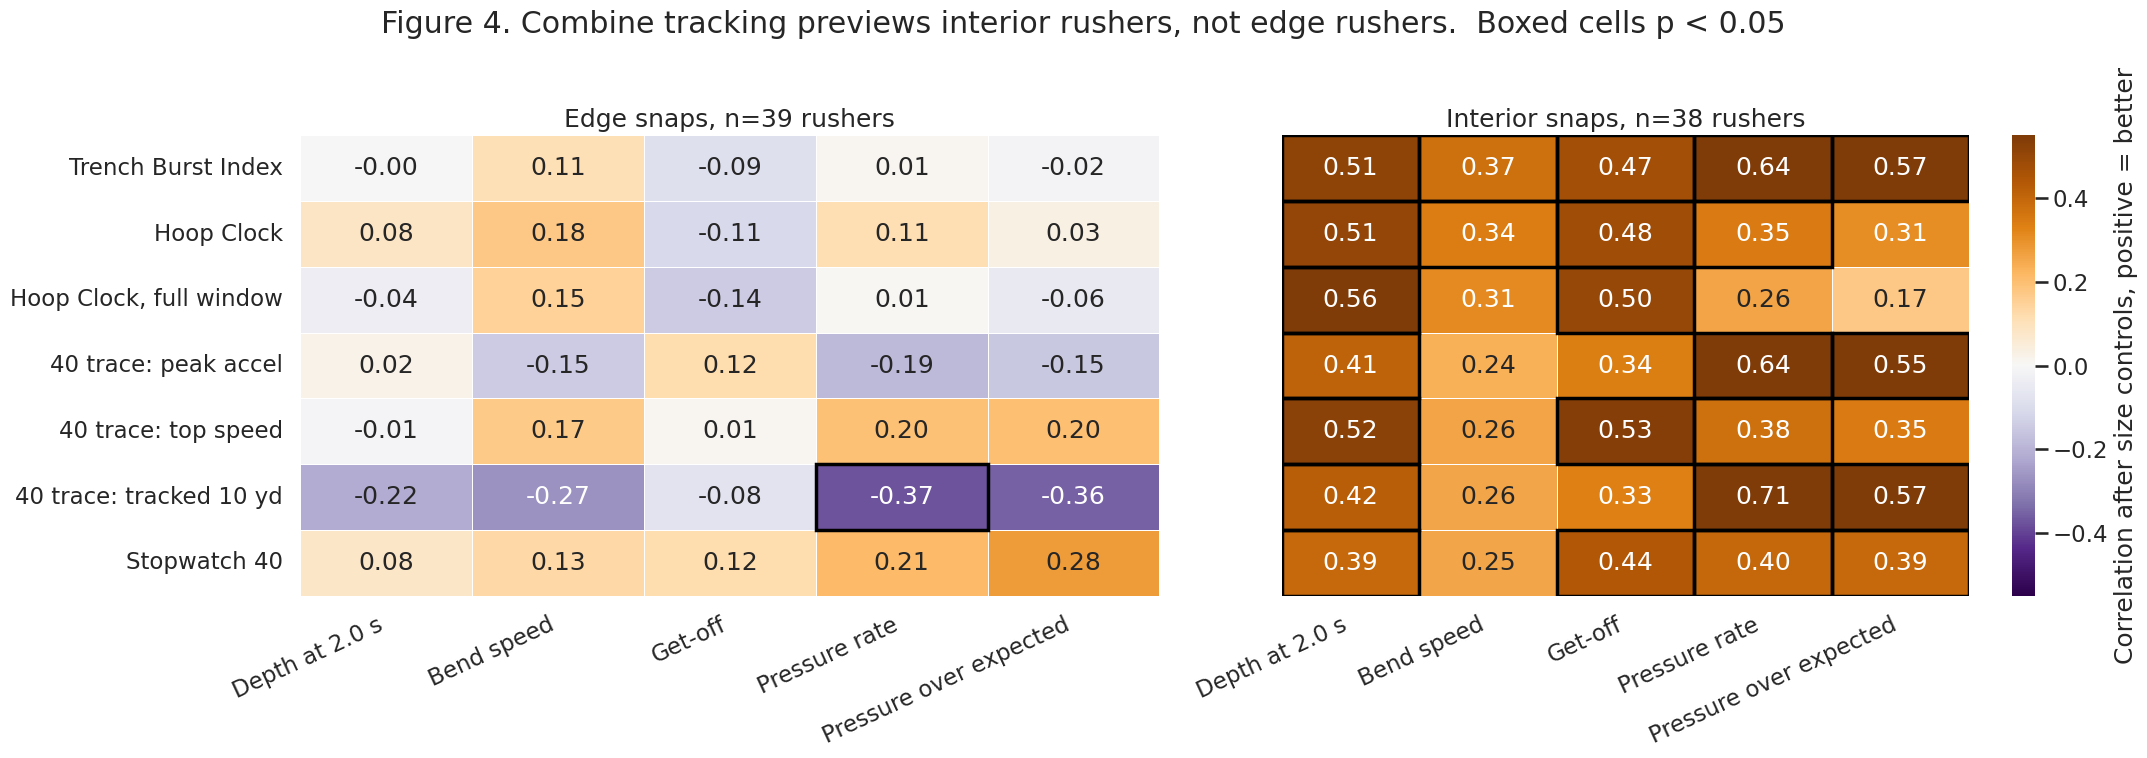

interior pressure rate, family wise p for best of six: {'Hoop Clock': (np.float64(0.35), np.float64(0.249)), 'Hoop Clock, full window': (np.float64(0.26), np.float64(0.558)), '40 trace: peak accel': (np.float64(0.64), np.float64(0.001)), '40 trace: top speed': (np.float64(0.38), np.float64(0.169)), '40 trace: tracked 10 yd': (np.float64(0.71), np.float64(0.0)), 'Stopwatch 40': (np.float64(0.4), np.float64(0.128))}
interior Trench Burst Index: +0.64 [+0.34, +0.82] p=0.0000 n=37
interior 40 trace: peak accel: +0.64 [+0.27, +0.84] p=0.0001 n=31
interior Hoop Clock: +0.35 [-0.05, +0.66] p=0.0412 n=35
hoop_clock size adjusted SD, edge 0.272 interior 0.365
t40_acc1 size adjusted SD, edge 0.626 interior 0.681


In [10]:
# Alignment on each snap: EDGE vs INTERIOR_LINE. Player rates are built from that alignment's snaps only
# Rebuild each player's numbers from his snaps at one alignment (EDGE or INTERIOR_LINE)
def align_df(al, min_n=80):
    sub = R[R.lined_up_position == al]
    A = sub.groupby("nfl_id").agg(
        n_al=("pressure", "size"),
        pr_al=("pressure", "sum"),
        xs_al=("xp", "sum"),
        **{c: (c, "mean") for c in ["dep10", "dep20", "g_v_bend", "g_s10", "player_get_off"]},
    )
    A = A[A.n_al >= min_n].copy()
    A["rate"] = (A.pr_al + a0) / (A.n_al + a0 + b0)
    A["poe"] = (A.pr_al - A.xs_al) / A.n_al * A.n_al / (A.n_al + a0 + b0)
    return A.join(meta).join(C)


# Two player tables: edge snaps and interior snaps
AL = {"Edge snaps": align_df("EDGE"), "Interior snaps": align_df("INTERIOR_LINE")}
for k, v in AL.items():
    print(
        k, "players", len(v), v.nfl_position.value_counts().to_dict(), "rushes", int(v.n_al.sum())
    )
labA = {
    "g_v_bend": "Bend speed",
    "dep20": "Depth at 2.0 s",
    "player_get_off": "Get-off",
    "rate": "Pressure rate",
    "poe": "Pressure over expected",
}
print("NFL movement vs pressure within alignment:")
for k, v in AL.items():
    print(
        " ",
        k,
        {
            labA[c]: (round(pc(v, c, "rate")[0], 2), round(pc(v, c, "poe")[0], 2))
            for c in ["g_v_bend", "dep20", "player_get_off"]
        },
    )
# Combine measures to compare, with sign so positive = faster
cm = {
    "cmi": ("Trench Burst Index", 1),
    "hoop_clock": ("Hoop Clock", -1),
    "hoop_window": ("Hoop Clock, full window", -1),
    "t40_acc1": ("40 trace: peak accel", 1),
    "t40_vmax": ("40 trace: top speed", 1),
    "t40_ten": ("40 trace: tracked 10 yd", -1),
    "forty": ("Stopwatch 40", -1),
}
outA = ["dep20", "g_v_bend", "player_get_off", "rate", "poe"]
HM = {}
HP = {}
HN = {}
for k, v in AL.items():
    m_ = pd.DataFrame(index=[cm[c][0] for c in cm], columns=[labA[o] for o in outA], dtype=float)
    p_m = m_.copy()
    for c in cm:
        for o in outA:
            r, p, n = pc(v, c, o)
            m_.loc[cm[c][0], labA[o]] = r * cm[c][1] * (-1 if o == "player_get_off" else 1)
            p_m.loc[cm[c][0], labA[o]] = p
            HN[(k, cm[c][0])] = n
    HM[k] = m_
    HP[k] = p_m
    print(k)
    print(m_.round(2).to_string())
# Figure 4: side by side heatmaps, boxed cells p < 0.05
fig, ax = plt.subplots(1, 2, figsize=(22, 7.5), sharey=True)
for a_, k in zip(ax, AL):
    sns.heatmap(
        HM[k],
        annot=True,
        fmt=".2f",
        cmap="PuOr_r",
        center=0,
        vmin=-0.55,
        vmax=0.55,
        ax=a_,
        cbar=(k == "Interior snaps"),
        linewidths=0.5,
        cbar_kws={"label": "Correlation after size controls, positive = better"},
    )
    for i_, rname in enumerate(HM[k].index):
        for j_, cname in enumerate(HM[k].columns):
            if HP[k].loc[rname, cname] < 0.05:
                a_.add_patch(plt.Rectangle((j_, i_), 1, 1, fill=False, edgecolor="black", lw=2.5))
    a_.set_title(f"{k}, n={len(AL[k])} rushers")
    a_.set_xlabel("")
    a_.set_xticklabels(a_.get_xticklabels(), rotation=25, ha="right")
ax[0].set_yticklabels(ax[0].get_yticklabels(), rotation=0)
fig.suptitle(
    "Figure 4. Combine tracking previews interior rushers, not edge rushers.  Boxed cells p < 0.05",
    y=1.02,
)
plt.tight_layout()
plt.savefig("fig4.png", dpi=150, bbox_inches="tight")
plt.show()
# family wise check inside: best of six single Combine measures on interior pressure rate
# Family wise check inside: best of six single measures on interior pressure rate
IN = AL["Interior snaps"]
rng = np.random.default_rng(13)
singles = [c for c in cm if c != "cmi"]


def maxabs_in(yv):
    best = 0
    for c in singles:
        x = IN[[c] + CTRL].assign(y=yv).dropna()
        if len(x) >= 15:
            best = max(best, abs(partial_multi(x[c].values, x.y.values, x[CTRL].values)[0]))
    return best


null = np.array([maxabs_in(rng.permutation(IN.rate.values)) for _ in range(1000)])
obs = {cm[c][0]: abs(pc(IN, c, "rate")[0]) for c in singles}
print(
    "interior pressure rate, family wise p for best of six:",
    {k: (round(v, 2), round(np.mean(null >= v), 3)) for k, v in obs.items()},
)
# Bootstrap intervals for the main interior results
for c in ["cmi", "t40_acc1", "hoop_clock"]:
    lo, hi = sorted(np.array(boot_partial(IN, c, "rate")) * cm[c][1])
    r, p, n = pc(IN, c, "rate")
    print(f"interior {cm[c][0]}: {r*cm[c][1]:+.2f} [{lo:+.2f}, {hi:+.2f}] p={p:.4f} n={n}")
# range restriction check: spread of size adjusted Combine measures by alignment group
# Range restriction check: is the size adjusted spread smaller on the edge?
for c in ["hoop_clock", "t40_acc1"]:
    x = Q[[c, "combine_weight", "interior"]].dropna()
    Xd = np.column_stack([np.ones(len(x)), x.combine_weight, x.interior])
    res_ = x[c] - Xd @ np.linalg.lstsq(Xd, x[c], rcond=None)[0]
    print(
        c,
        "size adjusted SD, edge %.3f interior %.3f"
        % (res_[x.interior == 0].std(), res_[x.interior == 1].std()),
    )

In [11]:
# Validation by draft class: the interior result within each class, and with each class left out
rows = []
for yr in sorted(IN.draft_year.dropna().unique()):
    r_in, p_in, n_in = pc(IN[IN.draft_year == yr], "cmi", "rate", ["combine_weight", "pick"])
    r_out, p_out, n_out = pc(IN[IN.draft_year != yr], "cmi", "rate")
    rows.append(
        {
            "class": int(yr),
            "within class r": r_in,
            "n": n_in,
            "left out, others r": r_out,
            "p (others)": p_out,
            "n others": n_out,
        }
    )
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Scouting board: interior DL ranked by size adjusted Trench Burst Index
sb = (
    IN[
        [
            "display_name",
            "nfl_position",
            "draft_year",
            "draft_round",
            "combine_weight",
            "cmi",
            "hoop_clock",
            "t40_acc1",
            "rate",
            "poe",
            "n_al",
        ]
        + ["pick"]
    ]
    .dropna(subset=["cmi"])
    .copy()
)
Xd = np.column_stack([np.ones(len(sb)), sb.combine_weight, sb.pick])
sb["tbi_adj"] = sb.cmi - Xd @ np.linalg.lstsq(Xd, sb.cmi, rcond=None)[0]
sb["tbi_pct"] = (sb.tbi_adj.rank(pct=True) * 100).round()
sb = sb.sort_values("tbi_adj", ascending=False)
show = sb[
    [
        "display_name",
        "nfl_position",
        "draft_year",
        "combine_weight",
        "tbi_pct",
        "hoop_clock",
        "rate",
        "poe",
        "n_al",
    ]
].copy()
show["rate"] = (show.rate * 100).round(1)
show["poe"] = (show.poe * 100).round(1)
print("Top 5")
print(show.head(5).to_string(index=False))
print("Bottom 5")
print(show.tail(5).to_string(index=False))
print(
    "pressure rate, top third vs bottom third of size adjusted TBI:",
    round(sb.head(len(sb) // 3).rate.mean() * 100, 1),
    round(sb.tail(len(sb) // 3).rate.mean() * 100, 1),
)

 class  within class r  n  left out, others r  p (others)  n others
  2023           0.713 14               0.570       0.004        23
  2024           0.748 12               0.581       0.002        25
  2025           0.360 11               0.765       0.000        26
Top 5
       display_name nfl_position  draft_year  combine_weight  tbi_pct  hoop_clock  rate  poe  n_al
Adetomiwa Adebawore           DT        2023             282    100.0    6.780935   9.3  1.5   445
     Brandon Dorlus           DT        2024             283     97.0    6.730131   9.2  1.0   258
       Zeek Biggers           DT        2025             321     95.0    7.313226   6.7 -1.6   109
     T'Vondre Sweat           NT        2024             366     92.0    7.830131   7.5 -0.0   520
       Braden Fiske           DE        2024             292     89.0    6.930131  11.5  3.4   610
Bottom 5
   display_name nfl_position  draft_year  combine_weight  tbi_pct  hoop_clock  rate  poe  n_al
     Tyler Lacy         

## 8. Rush level model

In [12]:
# Rush level model: every rush, expected pressure from context as an offset term, player clustered errors
import statsmodels.api as sm

# Rush level table with Combine features attached to every rush
RR = (
    R.merge(meta[["combine_weight", "interior", "pick"]].reset_index(), on="nfl_id")
    .merge(C.reset_index(), on="nfl_id", how="left")
    .merge(meta[["forty"]].reset_index(), on="nfl_id", how="left")
)
# Expected pressure on the logit scale enters as a covariate (context offset)
RR["lxp"] = np.log(RR.xp / (1 - RR.xp))
RR["inside_snap"] = (RR.lined_up_position == "INTERIOR_LINE").astype(int)
for c in ["combine_weight", "pick"]:
    RR[c + "_z"] = (RR[c] - RR[c].mean()) / RR[c].std()
# GEE logistic model, exchangeable correlation within player, odds ratio per SD faster
GE = {}
for c, sign in [("cmi", 1), ("t40_acc1", 1), ("hoop_clock", -1), ("forty", -1)]:
    for scope, d0 in [
        ("all rushes", RR),
        ("interior snaps", RR[RR.inside_snap == 1]),
        ("edge snaps", RR[RR.inside_snap == 0]),
    ]:
        d = d0.dropna(subset=[c]).copy()
        d["f"] = sign * (d[c] - RR[c].mean()) / RR[c].std()
        X = sm.add_constant(d[["lxp", "f", "combine_weight_z", "interior", "pick_z"]])
        m = sm.GEE(
            d.pressure,
            X,
            groups=d.nfl_id,
            family=sm.families.Binomial(),
            cov_struct=sm.cov_struct.Exchangeable(),
        ).fit()
        GE[(cm[c][0], scope)] = dict(
            players=d.nfl_id.nunique(),
            rushes=len(d),
            odds_ratio_per_SD=np.exp(m.params.f),
            lo=np.exp(m.conf_int().loc["f", 0]),
            hi=np.exp(m.conf_int().loc["f", 1]),
            p=m.pvalues.f,
        )
print(pd.DataFrame(GE).T.round(3).to_string())

                                     players   rushes  odds_ratio_per_SD     lo     hi      p
Trench Burst Index   all rushes         97.0  27135.0              1.109  1.002  1.227  0.046
                     interior snaps     88.0  12016.0              1.301  1.172  1.444  0.000
                     edge snaps         84.0  15119.0              0.970  0.853  1.102  0.638
40 trace: peak accel all rushes         77.0  21325.0              1.070  0.977  1.172  0.144
                     interior snaps     69.0  10493.0              1.197  1.081  1.324  0.001
                     edge snaps         67.0  10832.0              1.000  0.893  1.119  0.996
Hoop Clock           all rushes         90.0  25404.0              1.060  0.967  1.162  0.214
                     interior snaps     81.0  11613.0              1.143  1.001  1.305  0.049
                     edge snaps         78.0  13791.0              0.975  0.874  1.087  0.645
Stopwatch 40         all rushes         78.0  21446.0       

## 8b. Tracking versus the stopwatch
If the stopwatch 40 already carries the interior signal, Combine tracking only adds coverage. Here we hold the stopwatch 40 and 10 yard split constant and ask what tracking adds.

In [13]:
# Does Combine tracking add anything beyond the stopwatch 40 on interior snaps?
both = IN.dropna(subset=["cmi", "forty", "ten_yd_split"])
print(
    "interior rushers with TBI:",
    int(IN.cmi.notna().sum()),
    " with a stopwatch 40:",
    int(IN.forty.notna().sum()),
    " with both:",
    len(both),
)
tests = {
    "TBI alone": ("cmi", CTRL),
    "Stopwatch 40 alone": ("forty", CTRL),
    "TBI | stopwatch 40 and 10 yd": ("cmi", CTRL + ["forty", "ten_yd_split"]),
    "Stopwatch 40 | TBI": ("forty", CTRL + ["cmi"]),
    "Hoop Clock | stopwatch 40 and 10 yd": ("hoop_clock", CTRL + ["forty", "ten_yd_split"]),
    "40 peak accel | stopwatch 40 and 10 yd": ("t40_acc1", CTRL + ["forty", "ten_yd_split"]),
}
rows = []
for lab, (c, ctrl) in tests.items():
    for o in ["rate", "poe"]:
        r, p, n = pc(both, c, o, ctrl)
        rows.append(
            {
                "test": lab,
                "outcome": o,
                "r": r * (-1 if c in ["forty", "hoop_clock"] else 1),
                "p": p,
                "n": n,
            }
        )
TS = pd.DataFrame(rows).pivot(index="test", columns="outcome", values=["r", "p"]).round(3)
print(TS.to_string())

# Rush level: TBI and stopwatch 40 in the same GEE model, interior snaps
d = RR[(RR.inside_snap == 1)].dropna(subset=["cmi", "forty"]).copy()
d["tbi_z"] = (d.cmi - RR.cmi.mean()) / RR.cmi.std()
d["f40_z"] = -(d.forty - RR.forty.mean()) / RR.forty.std()
X = sm.add_constant(d[["lxp", "tbi_z", "f40_z", "combine_weight_z", "interior", "pick_z"]])
m = sm.GEE(
    d.pressure,
    X,
    groups=d.nfl_id,
    family=sm.families.Binomial(),
    cov_struct=sm.cov_struct.Exchangeable(),
).fit()
for v in ["tbi_z", "f40_z"]:
    lo, hi = np.exp(m.conf_int().loc[v])
    print(
        f"{v}: OR per SD {np.exp(m.params[v]):.3f} [{lo:.3f}, {hi:.3f}] p={m.pvalues[v]:.4f}  players {d.nfl_id.nunique()} rushes {len(d)}"
    )

# Coverage in rushes: how much of interior pass rush volume each measure can grade
cov_r = (
    R[R.lined_up_position == "INTERIOR_LINE"]
    .merge(C[["cmi"]].reset_index(), on="nfl_id", how="left")
    .merge(meta[["forty"]].reset_index(), on="nfl_id", how="left")
)
print(
    "share of interior rushes graded: TBI %.2f, stopwatch 40 %.2f"
    % (cov_r.cmi.notna().mean(), cov_r.forty.notna().mean())
)
# Weight range check for the scouting board
print(
    "interior DL weight range:",
    IN.combine_weight.min(),
    IN.combine_weight.max(),
    " 2nd heaviest:",
    IN.combine_weight.sort_values().iloc[-2],
)

interior rushers with TBI: 37  with a stopwatch 40: 31  with both: 31
                                            r             p       
outcome                                   poe   rate    poe   rate
test                                                              
40 peak accel | stopwatch 40 and 10 yd  0.600  0.676  0.000  0.000
Hoop Clock | stopwatch 40 and 10 yd     0.050  0.184  0.798  0.340
Stopwatch 40 alone                      0.392  0.398  0.029  0.027
Stopwatch 40 | TBI                      0.106 -0.012  0.571  0.949
TBI alone                               0.549  0.695  0.001  0.000
TBI | stopwatch 40 and 10 yd            0.501  0.675  0.004  0.000
tbi_z: OR per SD 1.287 [1.104, 1.501] p=0.0012  players 70 rushes 10505
f40_z: OR per SD 1.067 [0.912, 1.250] p=0.4176  players 70 rushes 10505
share of interior rushes graded: TBI 0.98, stopwatch 40 0.86
interior DL weight range: 257 366  2nd heaviest: 336


## 9. The Hoop Clock

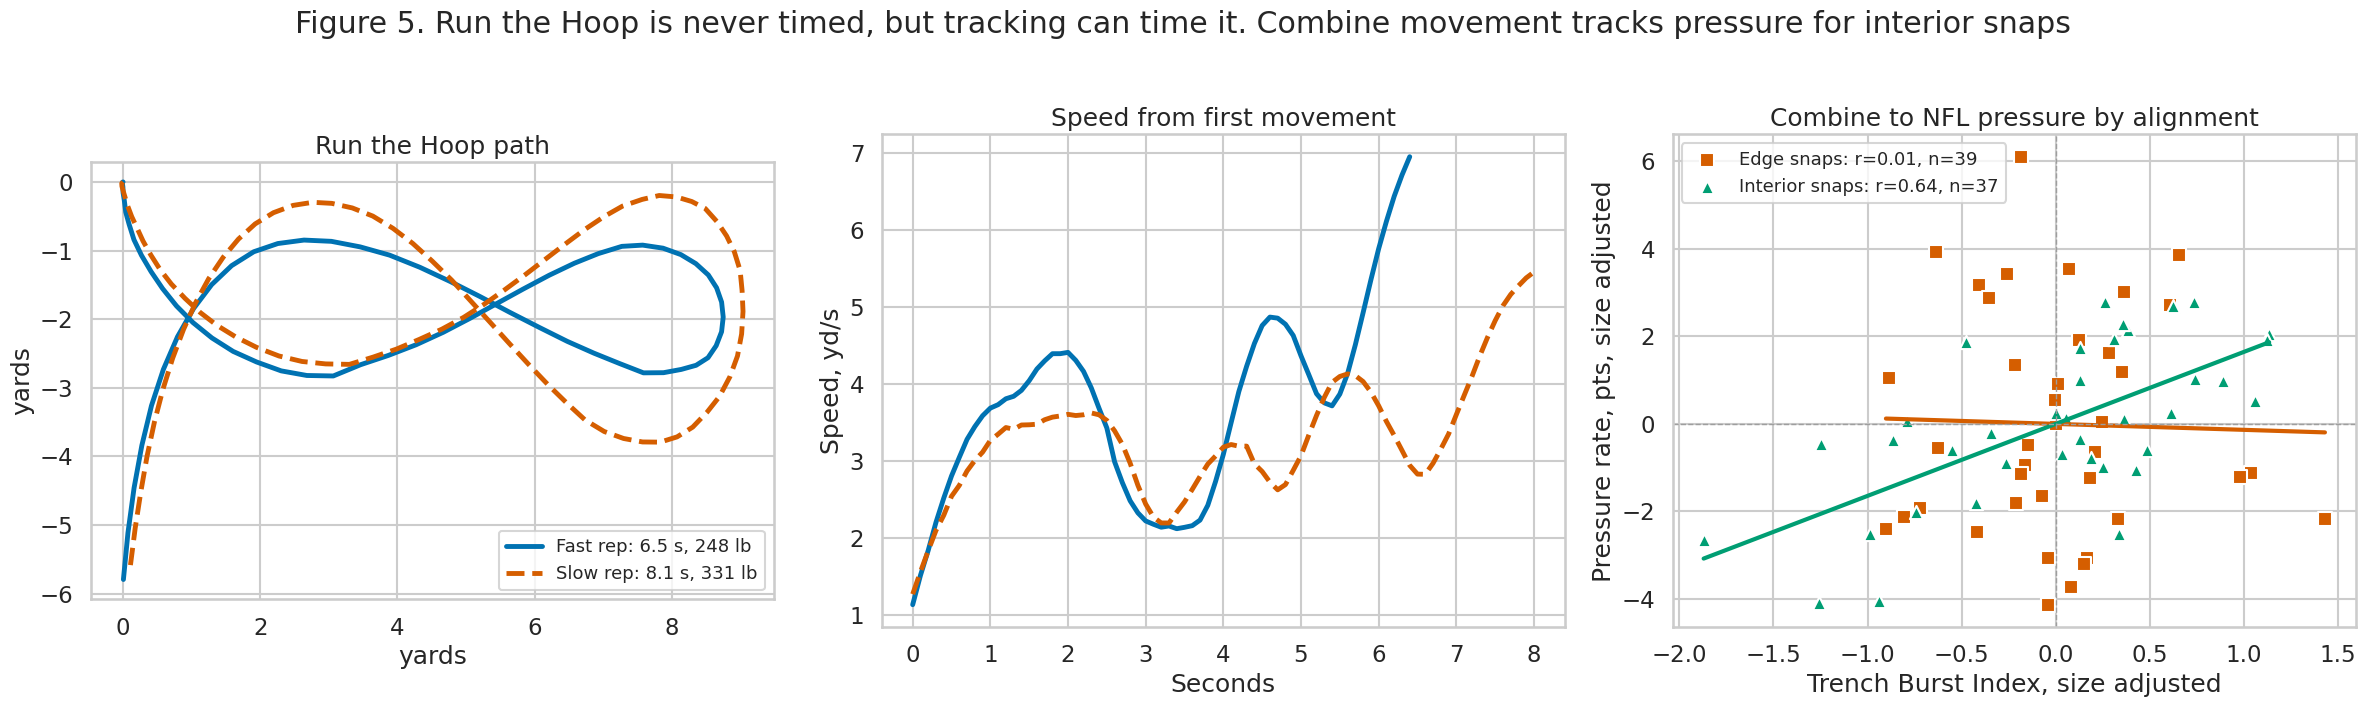

hoop clock reps 119 players 109 {'count': 119.0, 'mean': 7.23, 'std': 0.41, 'min': 6.2, '25%': 7.0, '50%': 7.2, '75%': 7.5, 'max': 8.3}
all DL: Hoop Clock vs Bend speed -0.31 p=0.0177 n=59
all DL: Hoop Clock vs Get-off +0.22 p=0.0919 n=59
all DL: Hoop Clock vs Pressure rate -0.26 p=0.0430 n=59


In [14]:
# Figure 5: a fast and a slow Run the Hoop rep
hp = dl[dl.drill_name == "RUN_THE_HOOP_DRILL"]
ex = E[E.drill == "RUN_THE_HOOP_DRILL"].dropna(subset=["hoop_clock"]).sort_values("hoop_clock")
fast, slow = ex.event_id.iloc[3], ex.event_id.iloc[-4]
fig, ax = plt.subplots(1, 3, figsize=(24, 7))
for eid, col, ls, lab in [(fast, BLUE, "-", "Fast rep"), (slow, ORANGE, "--", "Slow rep")]:
    d = hp[hp.event_id == eid].sort_values("time")
    on = np.argmax(d.s.values > 1.0)
    wt = meta.loc[d.nfl_id.iloc[0], "combine_weight"]
    ax[0].plot(
        d.x - d.x.iloc[0],
        d.y - d.y.iloc[0],
        color=col,
        ls=ls,
        lw=3.5,
        label=f"{lab}: {(len(d)-on)/10:.1f} s, {wt:.0f} lb",
    )
    ax[1].plot(np.arange(len(d) - on) / 10, d.s.values[on:], color=col, ls=ls, lw=3.5)
ax[0].set(title="Run the Hoop path", xlabel="yards", ylabel="yards")
ax[0].set_aspect("equal")
ax[0].legend(fontsize=13, loc="lower right")
ax[1].set(title="Speed from first movement", xlabel="Seconds", ylabel="Speed, yd/s")


# Partial residual plot: remove size controls from both axes
def resid(v, Z):
    Zm = np.column_stack([np.ones(len(v))] + [Z[:, i] for i in range(Z.shape[1])])
    return v - Zm @ np.linalg.lstsq(Zm, v, rcond=None)[0]


for k, col, mk in [("Edge snaps", ORANGE, "s"), ("Interior snaps", "#009E73", "^")]:
    x = AL[k][["cmi", "rate"] + CTRL].dropna()
    xr = resid(x.cmi.values, x[CTRL].values)
    yr = resid(x.rate.values * 100, x[CTRL].values)
    ax[2].scatter(
        xr,
        yr,
        c=col,
        marker=mk,
        s=90,
        edgecolor="white",
        label=f'{k}: r={pc(AL[k],"cmi","rate")[0]:.2f}, n={len(x)}',
    )
    bf = np.polyfit(xr, yr, 1)
    xx = np.linspace(xr.min(), xr.max(), 10)
    ax[2].plot(xx, np.polyval(bf, xx), color=col, lw=3)
ax[2].axhline(0, color=GREY, lw=1, ls="--")
ax[2].axvline(0, color=GREY, lw=1, ls="--")
ax[2].set(
    xlabel="Trench Burst Index, size adjusted",
    ylabel="Pressure rate, pts, size adjusted",
    title="Combine to NFL pressure by alignment",
)
ax[2].legend(fontsize=13, loc="upper left")
fig.suptitle(
    "Figure 5. Run the Hoop is never timed, but tracking can time it. Combine movement tracks pressure for interior snaps",
    y=1.02,
)
plt.tight_layout()
plt.savefig("fig5.png", dpi=150, bbox_inches="tight")
plt.show()
# Hoop Clock over expected for size
x = Q[["hoop_clock", "combine_weight", "interior"]].dropna()
Xd = np.column_stack([np.ones(len(x)), x.combine_weight, x.interior])
Q.loc[x.index, "hoop_oe"] = x.hoop_clock - Xd @ np.linalg.lstsq(Xd, x.hoop_clock, rcond=None)[0]
print(
    "hoop clock reps",
    len(ex),
    "players",
    ex.nfl_id.nunique(),
    ex.hoop_clock.describe().round(2).to_dict(),
)
for o in ["g_v_bend", "player_get_off", "press_eb"]:
    r, p, n = pc(Q, "hoop_clock", o)
    print(f"all DL: Hoop Clock vs {labO[o]} {r:+.2f} p={p:.4f} n={n}")

## 10. In season grade and names

expected bend = 4.625 + -0.0056*weight + -0.237*interior  rho bend_oe vs pressure 0.43  vs POE 0.43  n 65


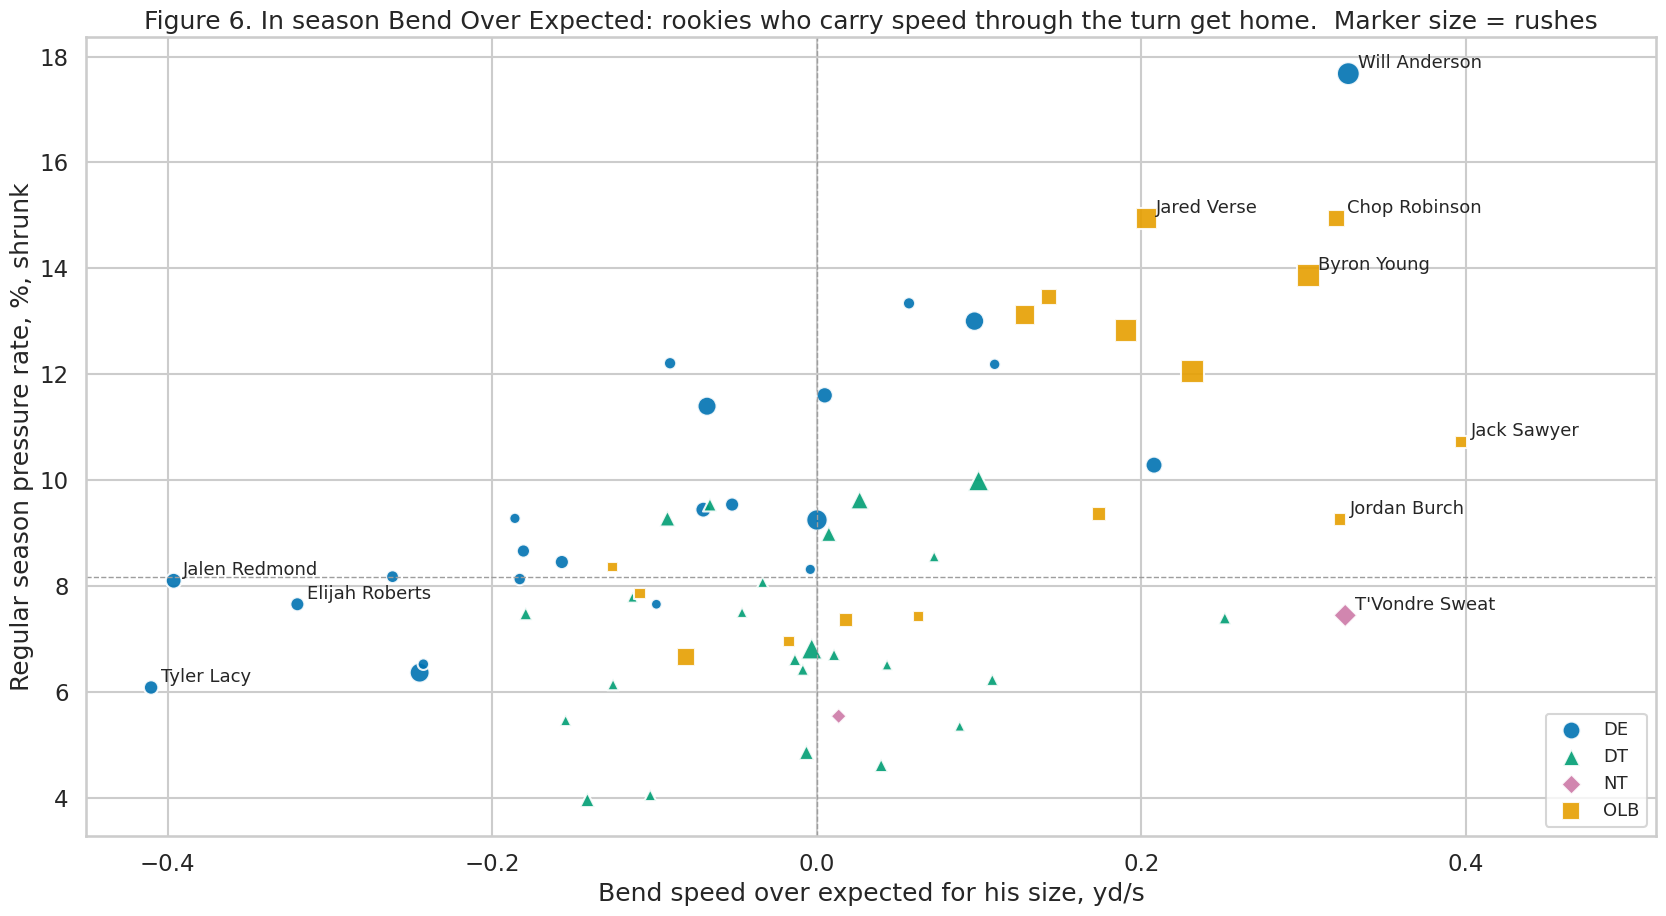

   display_name nfl_position  draft_year  combine_weight  g_v_bend  bend_oe  press_eb  poe_eb  n_rush
    Jack Sawyer          OLB        2025             260     3.564    0.397     0.107   0.001     146
  Will Anderson           DE        2023             253     3.533    0.327     0.177   0.059    1149
 T'Vondre Sweat           NT        2024             366     2.661    0.326     0.074  -0.000     521
   Jordan Burch          OLB        2025             279     3.382    0.322     0.093  -0.011     212
  Chop Robinson          OLB        2024             254     3.521    0.320     0.149   0.031     548
    Byron Young          OLB        2023             250     3.526    0.303     0.139   0.018    1202
Tyleik Williams           DT        2025             334     2.767    0.251     0.074   0.006     214
 Tuli Tuipulotu          OLB        2023             266     3.364    0.231     0.121   0.004    1193
 Lukas Van Ness           DE        2023             272     3.307    0.208     0.

In [15]:
# Bend speed over expected: residual after weight and alignment
x = (
    P[
        [
            "g_v_bend",
            "combine_weight",
            "interior",
            "press_eb",
            "poe_eb",
            "display_name",
            "nfl_position",
            "n_rush",
            "draft_year",
        ]
    ]
    .dropna()
    .copy()
)
Xd = np.column_stack([np.ones(len(x)), x.combine_weight, x.interior])
bb = np.linalg.lstsq(Xd, x.g_v_bend, rcond=None)[0]
x["bend_oe"] = x.g_v_bend - Xd @ bb
print(
    "expected bend = %.3f + %.4f*weight + %.3f*interior" % tuple(bb),
    " rho bend_oe vs pressure",
    round(stats.spearmanr(x.bend_oe, x.press_eb)[0], 2),
    " vs POE",
    round(stats.spearmanr(x.bend_oe, x.poe_eb)[0], 2),
    " n",
    len(x),
)
# Figure 7: bend grade vs pressure, with names
fig, ax = plt.subplots(figsize=(17, 9.5))
for pos in dl_pos:
    s = x[x.nfl_position == pos]
    ax.scatter(
        s.bend_oe,
        s.press_eb * 100,
        c=PAL[pos],
        marker=MK[pos],
        s=40 + s.n_rush / 5,
        edgecolor="white",
        alpha=0.9,
        label=pos,
    )
lab = pd.concat(
    [x.nlargest(6, "bend_oe"), x.nlargest(4, "press_eb"), x.nsmallest(3, "bend_oe")]
).drop_duplicates()
for _, r in lab.iterrows():
    ax.annotate(
        r.display_name,
        (r.bend_oe, r.press_eb * 100),
        xytext=(7, 4),
        textcoords="offset points",
        fontsize=13,
    )
ax.axvline(0, color=GREY, lw=1, ls="--")
ax.axhline(x.press_eb.median() * 100, color=GREY, lw=1, ls="--")
ax.set(
    xlabel="Bend speed over expected for his size, yd/s",
    ylabel="Regular season pressure rate, %, shrunk",
    title="Figure 6. In season Bend Over Expected: rookies who carry speed through the turn get home.  Marker size = rushes",
)
ax.set_xlim(x.bend_oe.min() - 0.04, x.bend_oe.max() + 0.12)
ax.legend(fontsize=13, loc="lower right")
plt.tight_layout()
plt.savefig("fig6.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    x.sort_values("bend_oe", ascending=False)[
        [
            "display_name",
            "nfl_position",
            "draft_year",
            "combine_weight",
            "g_v_bend",
            "bend_oe",
            "press_eb",
            "poe_eb",
            "n_rush",
        ]
    ]
    .head(12)
    .round(3)
    .to_string(index=False)
)
print(
    x.sort_values("bend_oe")[
        [
            "display_name",
            "nfl_position",
            "draft_year",
            "combine_weight",
            "bend_oe",
            "press_eb",
            "n_rush",
        ]
    ]
    .head(5)
    .round(3)
    .to_string(index=False)
)
# Hoop Clock over expected table, fastest and slowest for their size
tab = (
    Q.join(x[["bend_oe"]])
    .dropna(subset=["hoop_oe"])
    .sort_values("hoop_oe")[
        [
            "display_name",
            "nfl_position",
            "draft_year",
            "combine_weight",
            "hoop_clock",
            "hoop_oe",
            "bend_oe",
            "player_get_off",
            "press_eb",
            "n_rush",
        ]
    ]
)
print(tab.head(8).round(2).to_string(index=False))
print(tab.tail(5).round(2).to_string(index=False))
# Face check: where do the Defensive Rookies of the Year rank?
x["rank"] = x.bend_oe.rank(ascending=False).astype(int)
print(
    "award check, rank on bend over expected of",
    len(x),
    x[x.display_name.isin(["Will Anderson", "Jared Verse"])][
        ["display_name", "draft_year", "bend_oe", "rank"]
    ].to_string(index=False),
)

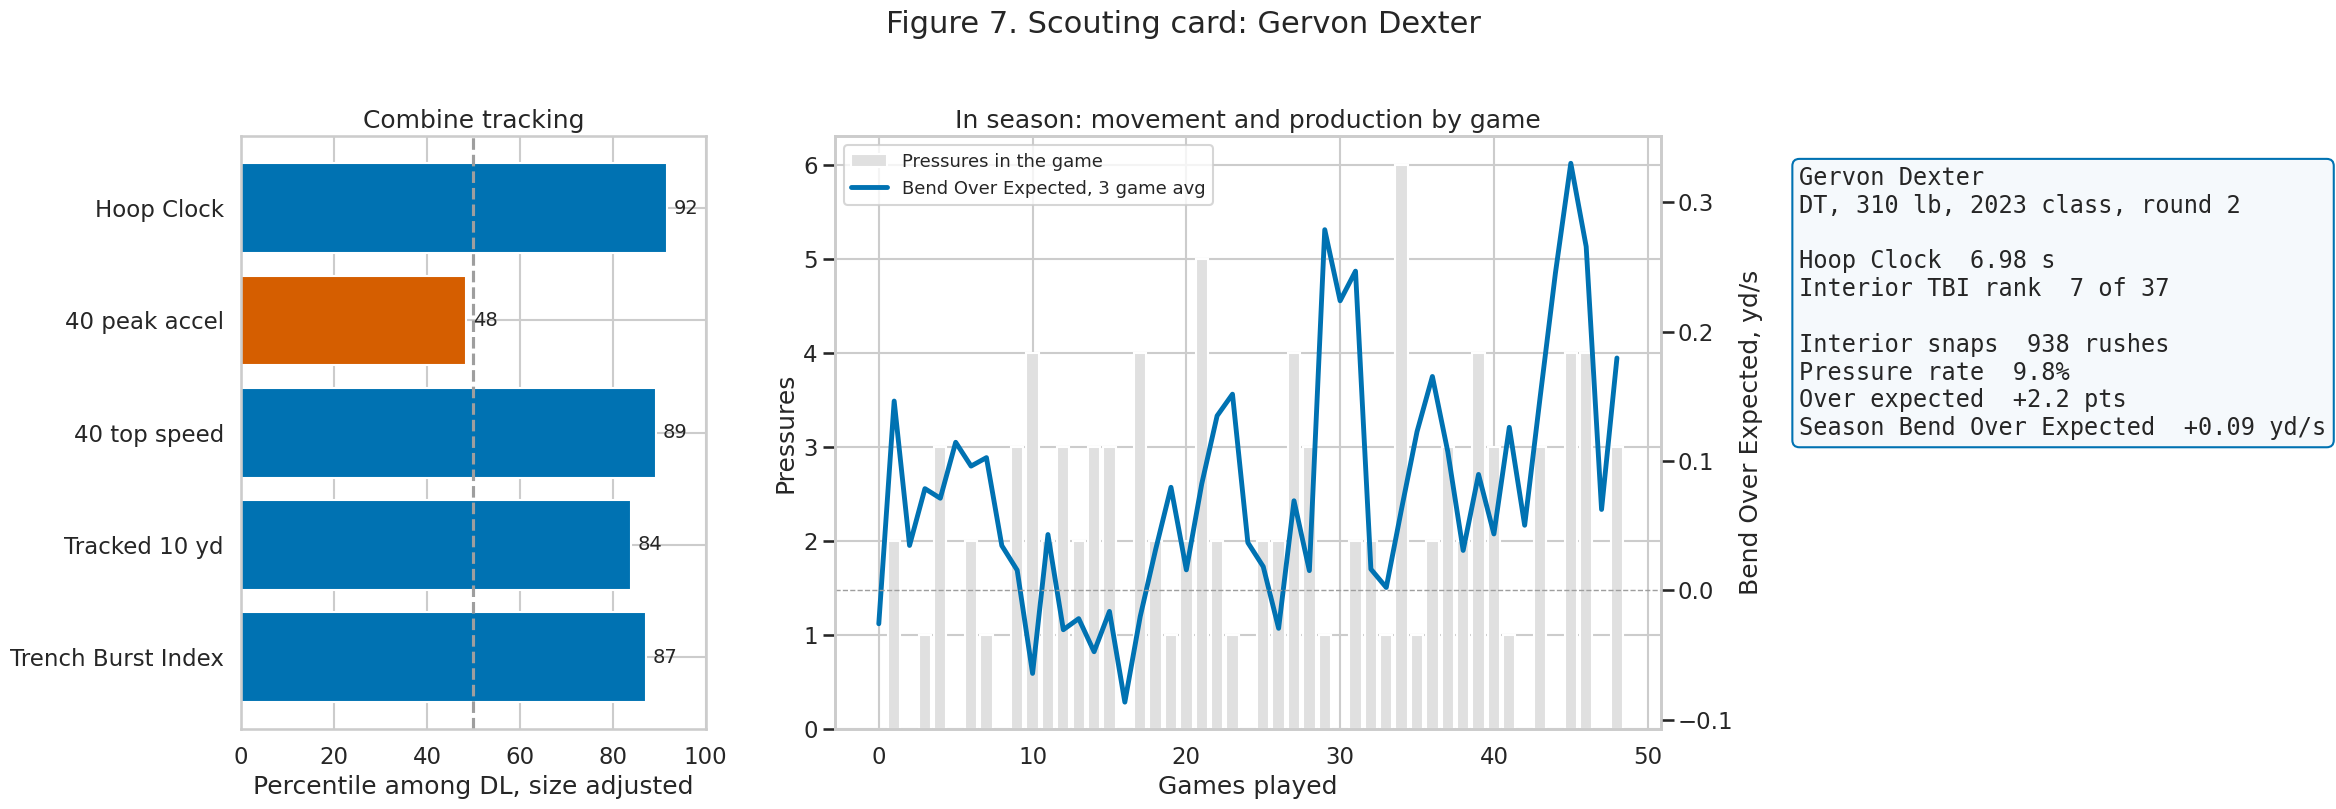

card player Gervon Dexter {'Hoop Clock': np.float64(91.74311926605505), '40 peak accel': np.float64(48.38709677419355), '40 top speed': np.float64(89.24731182795699), 'Tracked 10 yd': np.float64(83.87096774193549), 'Trench Burst Index': np.float64(87.17948717948718)}


In [16]:
# Figure 7: a one page scouting card for one interior DL
pid_c = meta.index[meta.display_name == "Gervon Dexter"][0]
pick_ = sb.loc[pid_c]
rank_ = list(sb.index).index(pid_c) + 1
cname = pick_.display_name
# Combine percentiles among all DL with tracking, size adjusted (weight and roster alignment)
CC = C.join(meta[["combine_weight", "interior"]]).dropna(subset=["combine_weight"])
pct = {}
for col_, lab_, sg_ in [
    ("hoop_clock", "Hoop Clock", -1),
    ("t40_acc1", "40 peak accel", 1),
    ("t40_vmax", "40 top speed", 1),
    ("t40_ten", "Tracked 10 yd", -1),
    ("cmi", "Trench Burst Index", 1),
]:
    d_ = CC[[col_, "combine_weight", "interior"]].dropna()
    Xd = np.column_stack([np.ones(len(d_)), d_.combine_weight, d_.interior])
    res_ = sg_ * (d_[col_] - Xd @ np.linalg.lstsq(Xd, d_[col_], rcond=None)[0])
    pct[lab_] = res_.rank(pct=True).get(pid_c, np.nan) * 100
# Weekly Bend Over Expected in games, using the size model from the in season grade
rr_ = R[R.nfl_id == pid_c].copy()
rr_["exp_bend"] = (
    bb[0] + bb[1] * meta.loc[pid_c, "combine_weight"] + bb[2] * meta.loc[pid_c, "interior"]
)
wk = (
    rr_.groupby(["season", "week"])
    .agg(
        boe=("g_v_bend", "mean"),
        exp=("exp_bend", "first"),
        press=("pressure", "sum"),
        rushes=("pressure", "size"),
    )
    .reset_index()
)
wk["boe"] = wk.boe - wk.exp
wk["t"] = np.arange(len(wk))
fig = plt.figure(figsize=(24, 8))
gs = fig.add_gridspec(1, 3, width_ratios=[0.9, 1.6, 0.9])
a0_, a1_, a2_ = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
ps_ = pd.Series(pct).dropna()
a0_.barh(ps_.index, ps_.values, color=[BLUE if v >= 50 else ORANGE for v in ps_.values])
a0_.axvline(50, color=GREY, ls="--")
a0_.set(xlim=(0, 100), xlabel="Percentile among DL, size adjusted", title="Combine tracking")
for i_, v in enumerate(ps_.values):
    a0_.text(v + 1.5, i_, f"{v:.0f}", va="center", fontsize=14)
a0_.invert_yaxis()
a1_.bar(wk.t, wk.press, color="#E0E0E0", label="Pressures in the game")
a1b = a1_.twinx()
a1b.plot(
    wk.t,
    wk.boe.rolling(3, min_periods=1).mean(),
    color=BLUE,
    lw=3.5,
    label="Bend Over Expected, 3 game avg",
)
a1b.axhline(0, color=GREY, ls="--", lw=1)
a1b.grid(False)
a1_.set(
    xlabel="Games played", ylabel="Pressures", title="In season: movement and production by game"
)
a1b.set_ylabel("Bend Over Expected, yd/s")
h1, l1 = a1_.get_legend_handles_labels()
h2, l2 = a1b.get_legend_handles_labels()
a1_.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=13)
a2_.axis("off")
txt = (
    f"{cname}\n{meta.loc[pid_c, 'nfl_position']}, {meta.loc[pid_c, 'combine_weight']:.0f} lb, {int(meta.loc[pid_c, 'draft_year'])} class, "
    f"{'round ' + str(int(meta.loc[pid_c, 'draft_round'])) if pd.notna(meta.loc[pid_c, 'draft_round']) else 'undrafted'}\n\n"
    f"Hoop Clock  {pick_.hoop_clock:.2f} s\n"
    f"Interior TBI rank  {rank_} of {len(sb)}\n\n"
    f"Interior snaps  {int(pick_.n_al)} rushes\n"
    f"Pressure rate  {pick_.rate * 100:.1f}%\n"
    f"Over expected  {pick_.poe * 100:+.1f} pts\n"
    f"Season Bend Over Expected  {wk.boe.mean():+.2f} yd/s"
)
a2_.text(
    0.02,
    0.95,
    txt,
    va="top",
    fontsize=17,
    family="monospace",
    bbox=dict(boxstyle="round", fc="#F5F9FC", ec=BLUE),
)
fig.suptitle(f"Figure 7. Scouting card: {cname}", y=1.02, fontsize=22)
plt.tight_layout()
plt.savefig("fig8.png", dpi=150, bbox_inches="tight")
plt.show()
print("card player", cname, pct)

## 11. Animation

strong pressure candidates: 55
 season  week possession_team yardline_side  yardline_number  down  yards_to_go pass_result  sack_f  dep20                                                                  play_description
   2024     1             TEN           TEN               29     3           12           S     1.0   5.08                (7:51) (Shotgun) W.Levis sacked at TEN 24 for -5 yards (G.Dexter).
   2024    13             DET           CHI                9     3            9           S     1.0   4.38                 (7:56) (Shotgun) J.Goff sacked at CHI 18 for -9 yards (G.Dexter).
   2025     1             MIN           MIN               33     3            2           S     1.0   4.34            (13:40) (Shotgun) J.McCarthy sacked at MIN 32 for -1 yards (G.Dexter).
   2025    15             CLE           CLE               20     3           10           S     1.0   4.14               (:34) (Shotgun) S.Sanders sacked at CLV 11 for -9 yards (G.Dexter).
   2025     6           

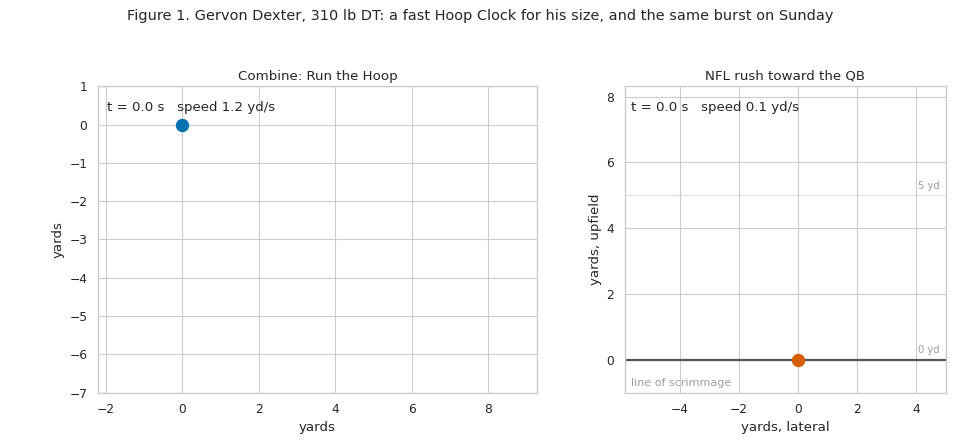

GIF play: TEN TEN 29 S 2024 week 1 (7:51) (Shotgun) W.Levis sacked at TEN 24 for -5 yards (G.Dexter).


In [17]:
# Figure 1: animated side by side, one player's Combine hoop rep and one of his NFL rushes
from matplotlib import animation
from IPython.display import Image as IPImage, display

# Pick a fast-for-size DT, his hoop rep and his deepest pressure rush
name = "Gervon Dexter"
pid = meta.index[meta.display_name == name][0]
h = hp[hp.nfl_id == pid]
h = h[h.event_id == h.event_id.iloc[0]].sort_values("time")
on = np.argmax(h.s.values > 1.0)
h = h.iloc[on:]
# Choose a pressure that ended the play badly for the offense: a sack, or a pass not completed
rp2 = R.merge(
    pp[["game_id", "play_id", "nfl_id", "pass_result", "sack", "play_description"]],
    on=["game_id", "play_id", "nfl_id"],
)
strong = rp2[
    (rp2.nfl_id == pid)
    & (rp2.pressure == 1)
    & (rp2.pass_result.isin(["S", "I", "IN"]) | (rp2.sack.fillna(0) > 0))
].copy()
strong["sack_f"] = strong.sack.fillna(0)
print("strong pressure candidates:", len(strong))
print(
    strong.sort_values(["sack_f", "dep20"], ascending=False)[
        [
            "season",
            "week",
            "possession_team",
            "yardline_side",
            "yardline_number",
            "down",
            "yards_to_go",
            "pass_result",
            "sack_f",
            "dep20",
            "play_description",
        ]
    ]
    .head(6)
    .to_string(index=False)
)
cand = strong.sort_values(["sack_f", "dep20"], ascending=False).iloc[0]
g = gt[
    (gt.game_id == cand.game_id) & (gt.play_id == cand.play_id) & (gt.nfl_id == pid)
].sort_values("rel")
# Coordinates relative to the start, game rush rotated so upfield is up
hx, hy = (h.x - h.x.iloc[0]).values, (h.y - h.y.iloc[0]).values
gx, gy = (g.sgn * (g.y - g.y0)).values, g.depth.values
n_f = max(len(h), len(g))
sns.set_context("notebook")
fig, ax = plt.subplots(1, 2, figsize=(12, 5.6), dpi=80, gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].set(
    xlim=(hx.min() - 1, hx.max() + 1),
    ylim=(hy.min() - 1, hy.max() + 1),
    title=f"Combine: Run the Hoop",
    xlabel="yards",
    ylabel="yards",
)
ax[0].set_aspect("equal")
ax[1].set(
    xlim=(min(gx.min(), -4) - 1, max(gx.max(), 4) + 1),
    ylim=(-1, max(gy.max(), 6) + 1),
    title="NFL rush toward the QB",
    xlabel="yards, lateral",
    ylabel="yards, upfield",
)
for yl in [v for v in range(0, 16, 5) if v <= ax[1].get_ylim()[1]]:
    ax[1].axhline(yl, color="#DDDDDD", lw=1, zorder=0)
    ax[1].text(ax[1].get_xlim()[1] - 0.2, yl + 0.2, f"{yl} yd", ha="right", fontsize=9, color=GREY)
ax[1].axhline(0, color="#555555", lw=2)
ax[1].text(0.02, 0.02, "line of scrimmage", transform=ax[1].transAxes, fontsize=10, color=GREY)
(l0,) = ax[0].plot([], [], color=BLUE, lw=3)
(d0,) = ax[0].plot([], [], "o", color=BLUE, ms=11)
t0_ = ax[0].text(0.02, 0.92, "", transform=ax[0].transAxes, fontsize=12)
(l1,) = ax[1].plot([], [], color=ORANGE, lw=3)
(d1,) = ax[1].plot([], [], "o", color=ORANGE, ms=11)
t1_ = ax[1].text(0.02, 0.92, "", transform=ax[1].transAxes, fontsize=12)
fig.suptitle(
    f'Figure 1. {name}, {meta.loc[pid,"combine_weight"]:.0f} lb DT: a fast Hoop Clock for his size, and the same burst on Sunday',
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))


# Draw one frame of both panels

i_go = int(round(cand.player_get_off * 10))
(mk_go,) = ax[1].plot([], [], "s", color="k", ms=9)
(mk_20,) = ax[1].plot([], [], "^", color="k", ms=10)
note_ = ax[1].text(0.02, 0.84, "", transform=ax[1].transAxes, fontsize=11)


def upd(i):
    j = min(i, len(h) - 1)
    k = min(i, len(g) - 1)
    l0.set_data(hx[: j + 1], hy[: j + 1])
    d0.set_data([hx[j]], [hy[j]])
    t0_.set_text(f"t = {j/10:.1f} s   speed {h.s.values[j]:.1f} yd/s")
    l1.set_data(gx[: k + 1], gy[: k + 1])
    d1.set_data([gx[k]], [gy[k]])
    t1_.set_text(f"t = {k/10:.1f} s   speed {g.s.values[k]:.1f} yd/s")
    if k >= i_go:
        mk_go.set_data([gx[min(i_go, len(gx) - 1)]], [gy[min(i_go, len(gy) - 1)]])
        note_.set_text("get-off" if k < 20 else "get-off, then 2.0 s depth")
    if k >= 20:
        mk_20.set_data([gx[20]], [gy[20]])
    return l0, d0, l1, d1, t0_, t1_, mk_go, mk_20, note_


# Render the GIF and show it inline
an = animation.FuncAnimation(fig, upd, frames=n_f + 12, interval=100, blit=True)
an.save("fig7.gif", writer=animation.PillowWriter(fps=10))
plt.close(fig)
print("gif frames", n_f, "size KB", round(os.path.getsize("fig7.gif") / 1024))
display(IPImage(filename="fig7.gif"))
sns.set_context("talk")
print(
    "GIF play:",
    cand.possession_team,
    cand.yardline_side,
    int(cand.yardline_number),
    cand.pass_result,
    int(cand.season),
    "week",
    int(cand.week),
    pp.loc[(pp.game_id == cand.game_id) & (pp.play_id == cand.play_id), "play_description"].iloc[0],
)

## 12. Robustness

In [18]:
# Hoop Clock under extra controls and subsets
rob = {}
for o in ["g_v_bend", "player_get_off", "press_eb"]:
    rob[labO[o]] = {
        "base controls": pc(Q, "hoop_clock", o)[0],
        "+ draft year": pc(Q, "hoop_clock", o, CTRL + ["draft_year"])[0],
        "+ height, arm length": pc(Q, "hoop_clock", o, CTRL + ["combine_height", "arm_length"])[0],
        "+ stopwatch 40 and 10 yd": pc(Q, "hoop_clock", o, CTRL + ["forty", "ten_yd_split"])[0],
        "edge only": pc(Q[Q.interior == 0], "hoop_clock", o, ["combine_weight", "pick"])[0],
        "interior only": pc(Q[Q.interior == 1], "hoop_clock", o, ["combine_weight", "pick"])[0],
        "200+ rushes": pc(Q[Q.n_rush >= 200], "hoop_clock", o)[0],
    }
print(pd.DataFrame(rob).round(2).to_string())
print(
    "bend -> pressure controlled, edge only %.2f, interior only %.2f"
    % (
        pc(P[P.interior == 0], "g_v_bend", "press_eb", ["combine_weight", "pick"])[0],
        pc(P[P.interior == 1], "g_v_bend", "press_eb", ["combine_weight", "pick"])[0],
    )
)
# Rep to rep reliability for players who ran the hoop twice
two = E[E.drill == "RUN_THE_HOOP_DRILL"].dropna(subset=["hoop_clock"])
two = two.assign(r=two.groupby("nfl_id").cumcount()).pivot_table(
    index="nfl_id", columns="r", values="hoop_clock"
)
t2 = two[[0, 1]].dropna()
print(
    "players with two hoop reps",
    len(t2),
    " rep to rep rho",
    round(stats.spearmanr(t2[0], t2[1])[0], 2),
)

                          Bend speed  Get-off  Pressure rate
base controls                  -0.31     0.22          -0.26
+ draft year                   -0.31     0.22          -0.26
+ height, arm length           -0.32     0.23          -0.26
+ stopwatch 40 and 10 yd       -0.16     0.20          -0.15
edge only                      -0.21     0.01          -0.16
interior only                  -0.47     0.29          -0.24
200+ rushes                    -0.39     0.30          -0.33
bend -> pressure controlled, edge only 0.55, interior only 0.53
players with two hoop reps 10  rep to rep rho 0.52


## 13. Negative control: offensive line
If the interior DL result only meant that the 40 is a good test, it should also show up for blockers. We apply the same 40 yard trace index, top speed, peak acceleration and tracked 10 yard time with no hoop, to pass protection: pressure allowed, pressure allowed over a context model, and the NGS peak pressure probability allowed.

In [19]:
# Offensive line pass block snaps, regular season
ol_ids = set(players.loc[players.nfl_position.isin(["T", "G", "C"]), "nfl_id"])
ob = pp[
    pp.nfl_id.isin(ol_ids)
    & pp.game_id.isin(reg_games)
    & pp.pressure_allowed.notna()
    & (pp.play_nullified_by_penalty.fillna("N") != "Y")
].copy()
ob["pa"] = ob.pressure_allowed.astype(float)
ob["ydl100"] = np.where(
    ob.yardline_side == ob.possession_team, 100 - ob.yardline_number, ob.yardline_number
)
for c in cat:
    ob[c] = ob[c].fillna("NA").astype("category")
# Expected pressure allowed from context, players held out
FE_OL = [
    "down",
    "yards_to_go",
    "quarter",
    "ydl100",
    "pre_snap_home_team_win_probability",
    "dropback_duration",
    "pass_rushers_encountered",
] + cat
o = np.zeros(len(ob))
for tr, te in GroupKFold(5).split(ob, ob.pa, ob.nfl_id):
    m = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=200,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=0,
        verbose=-1,
    )
    m.fit(ob[FE_OL].iloc[tr], ob.pa.iloc[tr])
    o[te] = m.predict_proba(ob[FE_OL].iloc[te])[:, 1]
ob["xpa"] = o
ob["inside_snap"] = ob.lined_up_position.astype(str).isin(["G", "C"]).astype(int)
print(
    f"OL pass block snaps {len(ob):,}, players {ob.nfl_id.nunique()}, pressure allowed rate {ob.pa.mean():.3f}, context AUC {roc_auc_score(ob.pa, o):.3f}"
)
# Same 40 yard trace index for OL players
OC = F40[F40.index.isin(ol_ids)].copy()
OC["idx40"] = pd.concat([zs(OC.t40_vmax), zs(OC.t40_acc1), -zs(OC.t40_ten)], axis=1).mean(
    axis=1, skipna=True
)


# Player table for one alignment with shrunk pressure allowed rates
def ol_df(mask, min_n=150):
    A = (
        ob[mask]
        .groupby("nfl_id")
        .agg(
            n=("pa", "size"),
            k=("pa", "sum"),
            xk=("xpa", "sum"),
            ppp=("peak_pressure_probability_allowed", "mean"),
        )
    )
    p_ = A.k / A.n
    s_ = A.n >= min_n
    m_, v_ = p_[s_].mean(), p_[s_].var()
    kk = m_ * (1 - m_) / v_ - 1
    a_, b_ = m_ * kk, (1 - m_) * kk
    A["rate"] = (A.k + a_) / (A.n + a_ + b_)
    A["poe"] = (A.k - A.xk) / (A.n + a_ + b_)
    A = A[A.n >= min_n].join(meta.drop(columns=["interior"])).join(OC)
    A["interior"] = A.nfl_position.isin(["G", "C"]).astype(int)
    return A


# Controlled correlations, positive = faster at the Combine allows less pressure
OLR = {}
for k, msk in [("Tackle snaps", ob.inside_snap == 0), ("Interior snaps", ob.inside_snap == 1)]:
    A = ol_df(msk)
    OLR[k] = {
        f"{lab}": round(-pc(A, "idx40", o_)[0], 2)
        for o_, lab in [
            ("rate", "pressure allowed"),
            ("poe", "pressure allowed over expected"),
            ("ppp", "peak pressure probability"),
        ]
    } | {"n": int(A.idx40.notna().sum())}
print("40 trace index vs pass protection, positive = faster at the Combine allows less pressure")
print(pd.DataFrame(OLR).T.to_string())

OL pass block snaps 48,697, players 89, pressure allowed rate 0.084, context AUC 0.783
40 trace index vs pass protection, positive = faster at the Combine allows less pressure
                pressure allowed  pressure allowed over expected  peak pressure probability     n
Tackle snaps                0.19                            0.09                       0.14  23.0
Interior snaps             -0.22                           -0.22                      -0.11  28.0


In [20]:
# Official name spelling for players named in the writeup
print(players[players.display_name.str.contains("Anderson|Sweat|Verse|Dexter|Sawyer", na=False)][["display_name", "nfl_position", "draft_year"]].to_string(index=False))

  display_name nfl_position  draft_year
 Will Anderson           DE        2023
 Gervon Dexter           DT        2023
   Jared Verse          OLB        2024
T'Vondre Sweat           NT        2024
   Jack Sawyer          OLB        2025


## References

* ESPN Analytics, 2026 NFL pass rush, run stop and blocking win rate rankings. Pass rush win rate counts a rusher beating his block within 2.5 seconds. https://www.espn.com/nfl/story/_/id/46138675/2025-nfl-win-rates-top-teams-players-rankings-pass-run-block
* PFF, Edge vs Interior: which pass rusher reigns supreme. Season-to-season stability of pressure rate by alignment, value of pressure by alignment and by time to pressure. https://www.pff.com/news/pro-edge-vs-interior-which-pass-rusher-reigns-supreme
* PFF, NFL pass-rusher rankings after the 2025 regular season. Pass rush win rate leaders. https://www.pff.com/news/nfl-pass-rusher-rankings-2025-regular-season
* NFL Next Gen Stats, New advanced metrics for the 2025 NFL season. https://www.nfl.com/news/next-gen-stats-new-advanced-metrics-you-need-to-know-for-the-2025-nfl-season